<a href="https://www.kaggle.com/code/lalit7881/indian-retail-sales-analytics-eda-99?scriptVersionId=358870655" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vigneshpgd/indian-retail-sales-analytics-dataset/sales_data.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/vigneshpgd/indian-retail-sales-analytics-dataset/sales_data.csv")

In [3]:
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


In [4]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
14995,ORD109942,2025-12-31,CUST10397,West,Pune,Consumer,Online,Beauty,Skincare,P1004,...,0.20,14813.34,2962.67,11850.67,5930.88,4262.25,4,Yes,3,Debit Card
14996,ORD101325,2025-12-31,CUST11524,South,Bengaluru,Consumer,Retail Store,Technology,Accessories,P1013,...,0.00,2853.60,0.00,2853.60,1985.23,868.37,5,No,3,Debit Card
14997,ORD107747,2025-12-31,CUST11321,East,Guwahati,Consumer,Online,Furniture,Chairs,P1022,...,0.00,2749.28,0.00,2749.28,1795.97,953.31,2,No,3,Net Banking
14998,ORD105862,2025-12-31,CUST11426,East,Guwahati,Consumer,Online,Beauty,Personal Care,P1004,...,0.25,10019.80,2504.95,7514.85,4022.03,3492.82,8,No,3,Credit Card
14999,ORD102445,2025-12-31,CUST10296,East,Kolkata,Consumer,Online,Office Supplies,Pens,P1055,...,0.30,5831.00,1749.30,4081.70,2212.60,1869.10,4,No,4,Credit Card


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               15000 non-null  object 
 1   Order_Date             15000 non-null  object 
 2   Customer_ID            15000 non-null  object 
 3   Region                 15000 non-null  object 
 4   City                   15000 non-null  object 
 5   Segment                15000 non-null  object 
 6   Channel                15000 non-null  object 
 7   Category               15000 non-null  object 
 8   Subcategory            15000 non-null  object 
 9   Product_ID             15000 non-null  object 
 10  Quantity               15000 non-null  int64  
 11  Unit_Price_INR         15000 non-null  float64
 12  Discount               15000 non-null  float64
 13  Sales_INR              15000 non-null  float64
 14  Discount_Amount_INR    15000 non-null  float64
 15  Ne

In [6]:
df.describe()

,Quantity,Unit_Price_INR,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Customer_Satisfaction
count,15000.000000,15000.00000,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.00000
mean,3.991333,1347.45306,0.106630,5396.765599,578.66473,4818.100912,2960.555138,1818.571167,3.678133,3.54920
std,1.993370,973.90804,0.087742,5225.206681,863.70892,4700.051718,2919.123008,1821.210884,1.669228,0.73522
min,1.000000,150.00000,0.000000,150.000000,0.00000,119.780000,75.110000,39.230000,1.000000,1.00000
25%,2.000000,708.49000,0.050000,2033.355000,17.45500,1793.360000,1090.092500,663.167500,2.000000,3.00000
50%,4.000000,1092.60500,0.100000,3901.345000,298.30500,3462.510000,2110.155000,1279.100000,4.000000,4.00000
75%,6.000000,1692.42750,0.150000,6949.402500,745.05250,6230.482500,3812.557500,2334.192500,5.000000,4.00000
max,7.000000,18616.06000,0.300000,130312.420000,13031.24000,117281.180000,70176.380000,47104.800000,8.000000,5.00000


In [7]:
df.isnull().sum()

Order_ID                 0
Order_Date               0
Customer_ID              0
Region                   0
City                     0
Segment                  0
Channel                  0
Category                 0
Subcategory              0
Product_ID               0
Quantity                 0
Unit_Price_INR           0
Discount                 0
Sales_INR                0
Discount_Amount_INR      0
Net_Sales_INR            0
Cost_INR                 0
Profit_INR               0
Shipping_Days            0
Returned                 0
Customer_Satisfaction    0
Payment_Method           0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

Order_ID                  object
Order_Date                object
Customer_ID               object
Region                    object
City                      object
Segment                   object
Channel                   object
Category                  object
Subcategory               object
Product_ID                object
Quantity                   int64
Unit_Price_INR           float64
Discount                 float64
Sales_INR                float64
Discount_Amount_INR      float64
Net_Sales_INR            float64
Cost_INR                 float64
Profit_INR               float64
Shipping_Days              int64
Returned                  object
Customer_Satisfaction      int64
Payment_Method            object
dtype: object

In [10]:
df.shape

(15000, 22)

In [11]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City', 'Segment',
       'Channel', 'Category', 'Subcategory', 'Product_ID', 'Quantity',
       'Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR',
       'Net_Sales_INR', 'Cost_INR', 'Profit_INR', 'Shipping_Days', 'Returned',
       'Customer_Satisfaction', 'Payment_Method'],
      dtype='object')

In [12]:
df.nunique

<bound method DataFrame.nunique of         Order_ID  Order_Date Customer_ID   Region        City    Segment  \
0      ORD111444  2024-01-01   CUST10128     West        Pune  Corporate   
1      ORD102034  2024-01-01   CUST10316     West   Ahmedabad  Corporate   
2      ORD106623  2024-01-01   CUST11764    South     Chennai   Consumer   
3      ORD113951  2024-01-01   CUST12447  Central      Raipur   Consumer   
4      ORD105177  2024-01-01   CUST10691    North  Chandigarh   Consumer   
...          ...         ...         ...      ...         ...        ...   
14995  ORD109942  2025-12-31   CUST10397     West        Pune   Consumer   
14996  ORD101325  2025-12-31   CUST11524    South   Bengaluru   Consumer   
14997  ORD107747  2025-12-31   CUST11321     East    Guwahati   Consumer   
14998  ORD105862  2025-12-31   CUST11426     East    Guwahati   Consumer   
14999  ORD102445  2025-12-31   CUST10296     East     Kolkata   Consumer   

            Channel         Category    Subcategory 

## EDA

SALES DATASET: EXPLORATORY DATA ANALYSIS
Rows: 15,000
Columns after feature engineering: 30
Unique orders: 15,000
Unique customers: 2,496
Unique products: 99
Date range: 2024-01-01 00:00:00 to 2025-12-12 00:00:00
Duplicate rows: 0

Missing values in original columns:


,Missing_Count
Order_ID,0
Order_Date,9156
Customer_ID,0
Region,0
City,0
Segment,0
Channel,0
Category,0
Subcategory,0
Product_ID,0



KEY PERFORMANCE INDICATORS


,Metric,Value
0,Gross Sales,80951483.98
1,Net Sales,72271513.68
2,Total Profit,27278567.50
3,Total Cost,44408327.07
4,Total Discount,8679970.95
5,Units Sold,59870.00
6,Unique Orders,15000.00
7,Unique Customers,2496.00
8,Average Order Value,4818.10
9,Profit Margin %,37.74


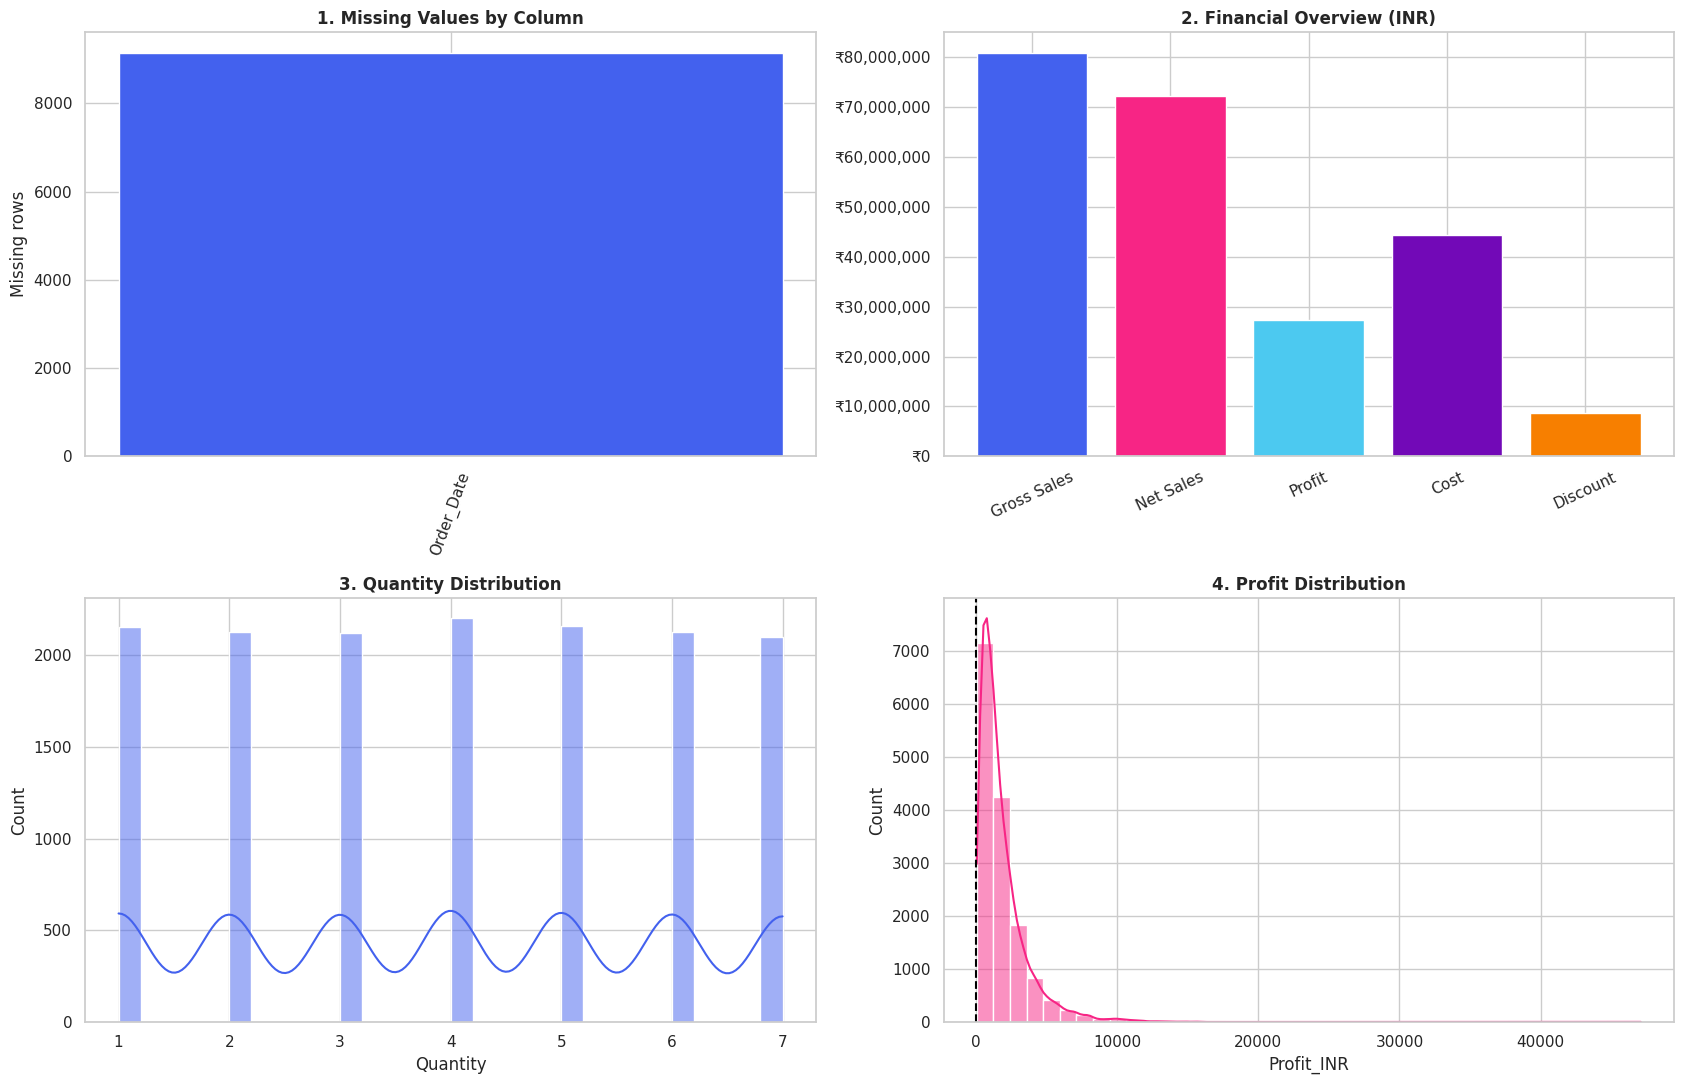

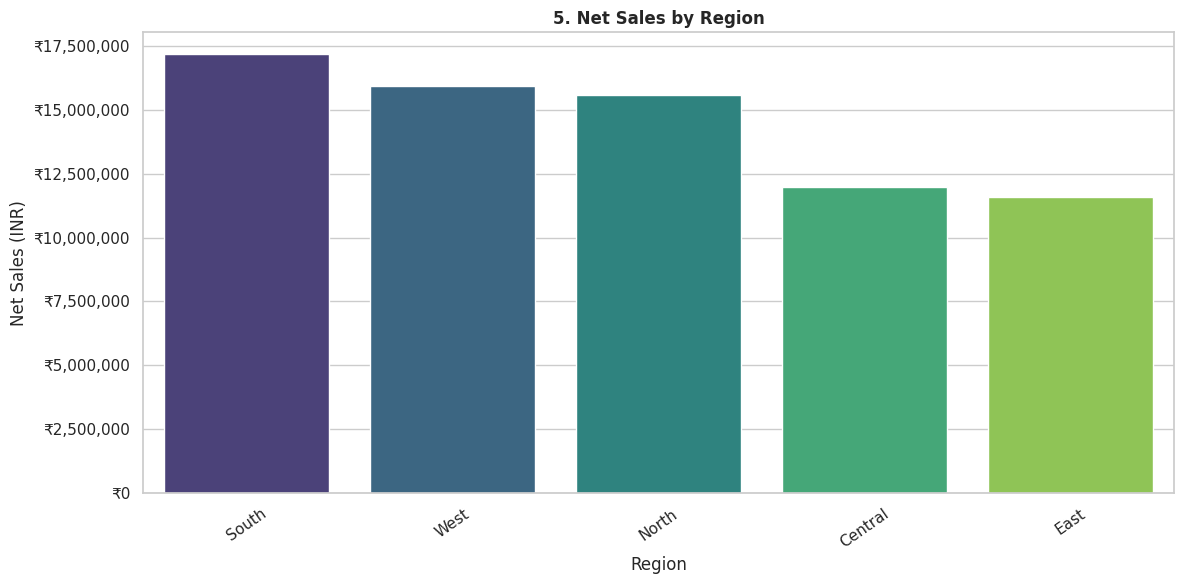

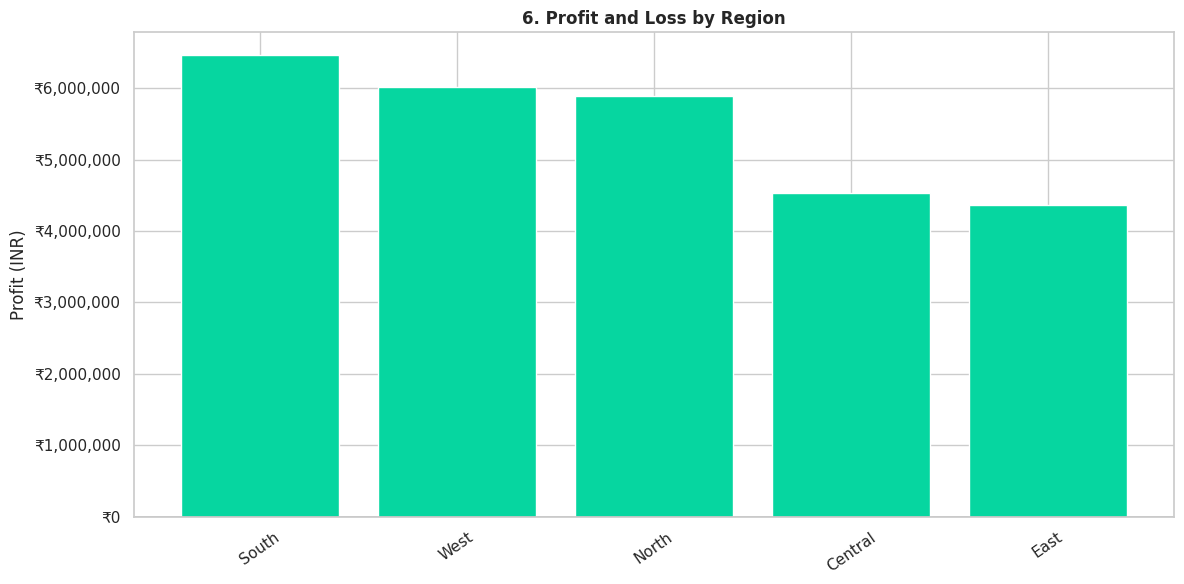

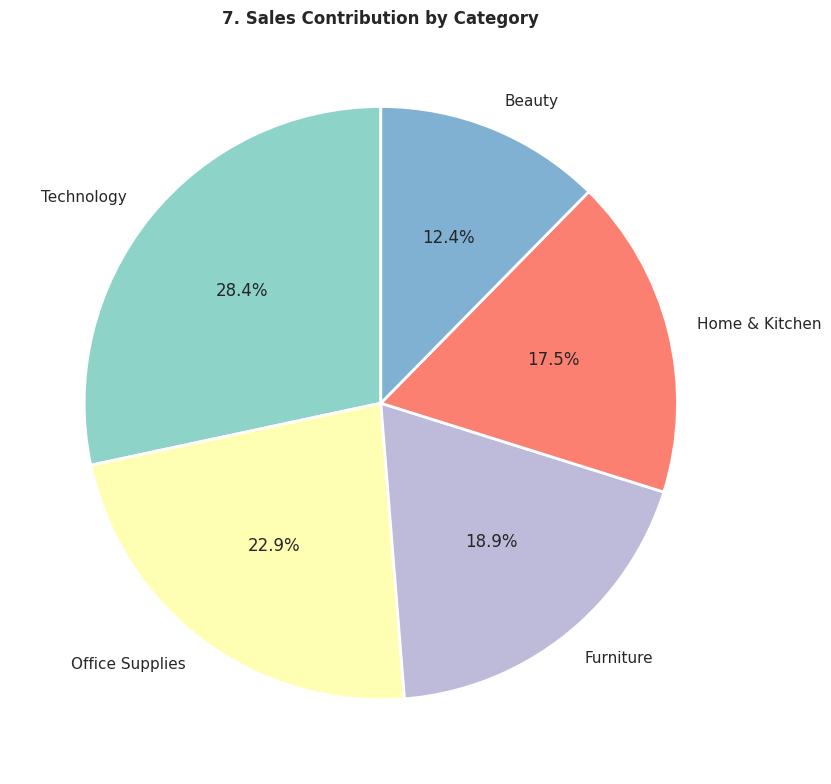

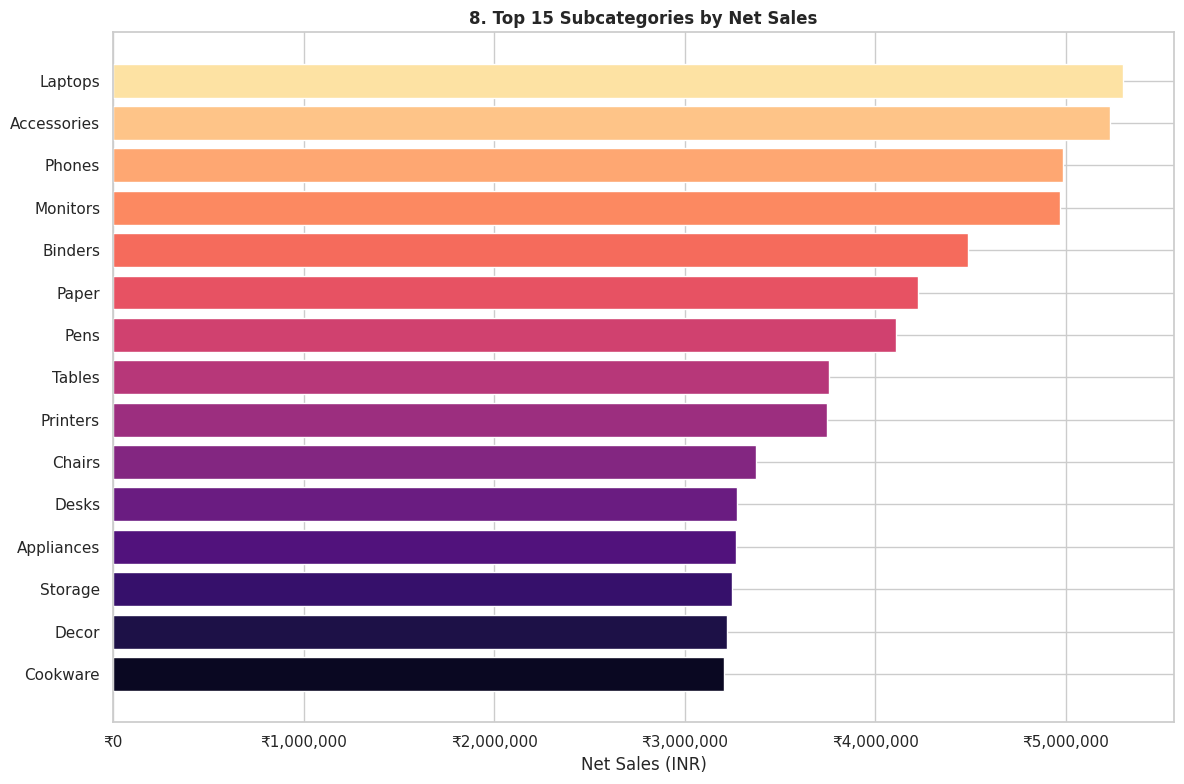

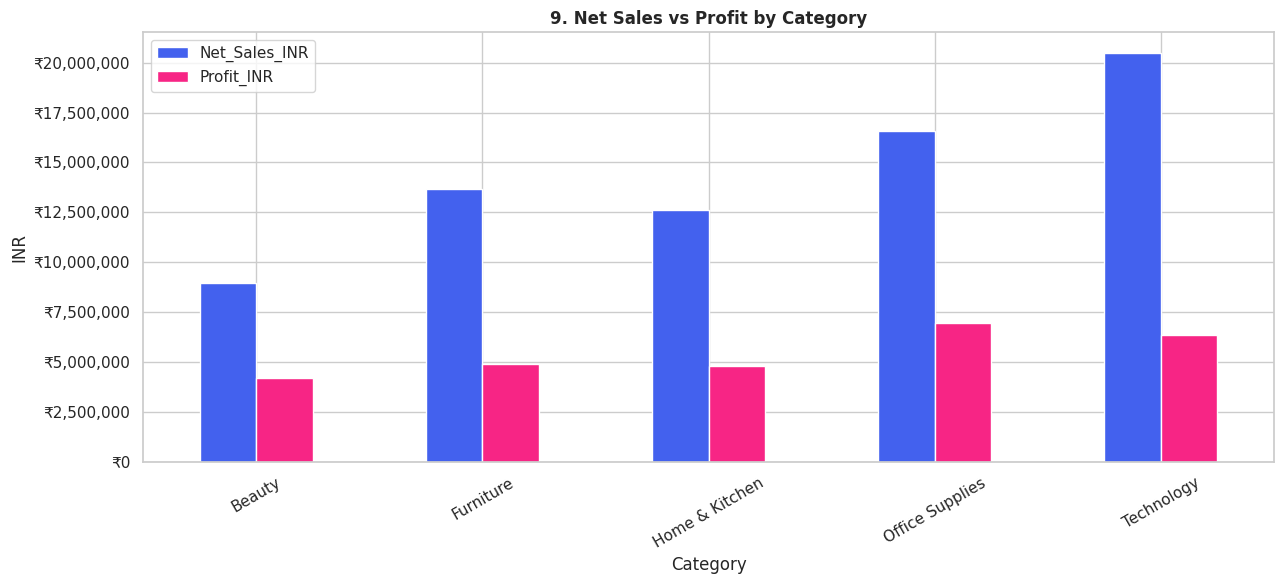

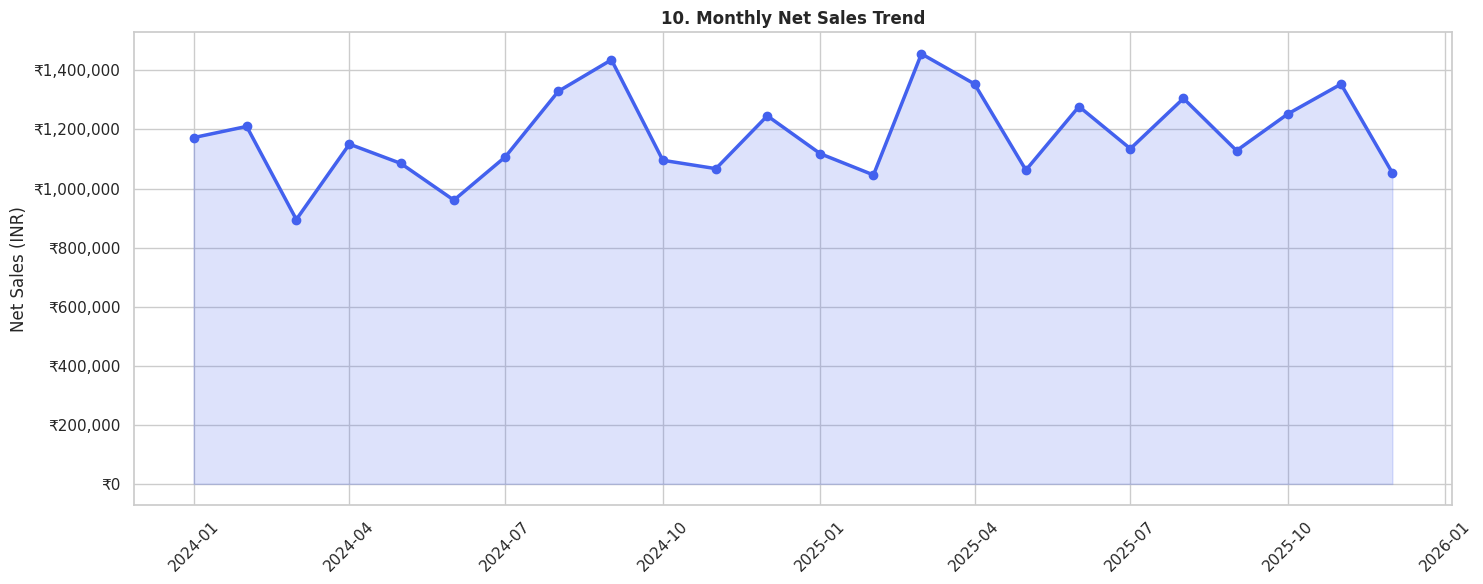

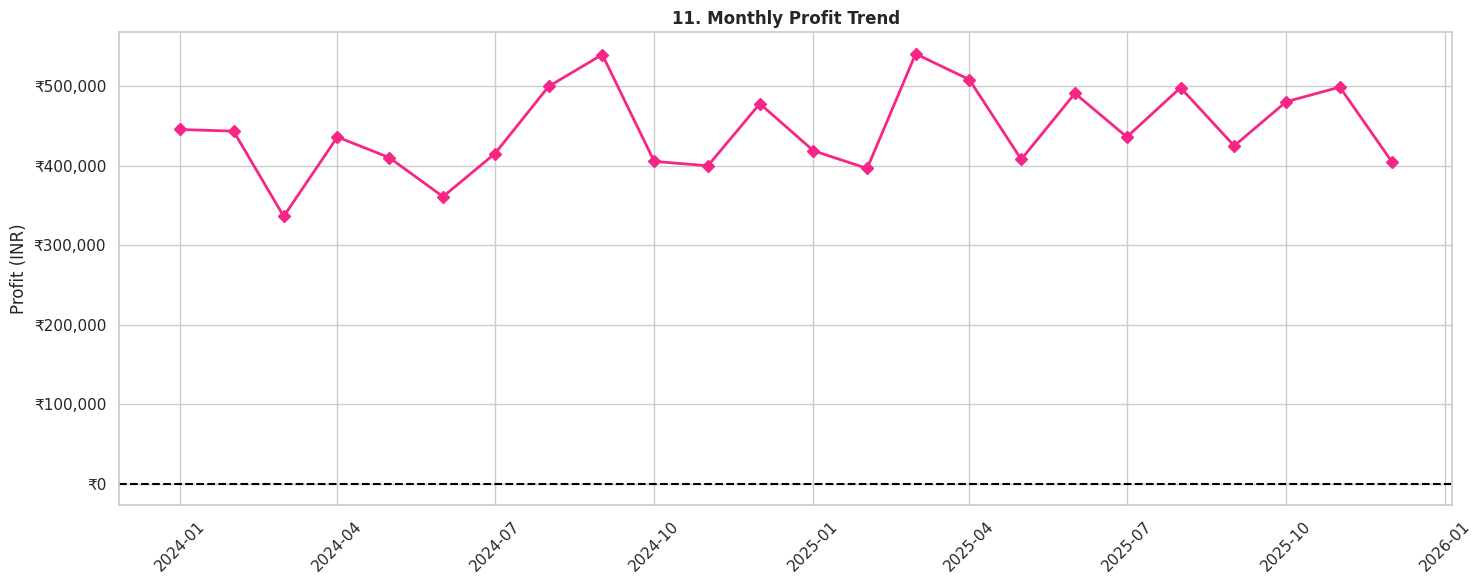

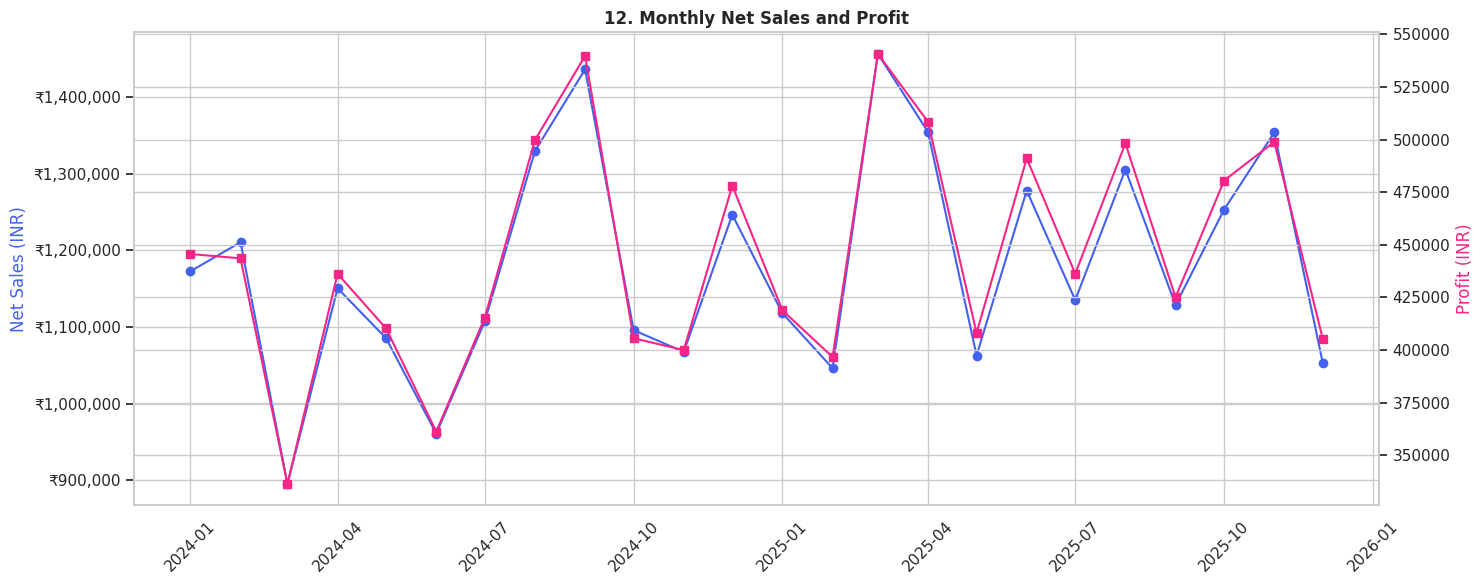

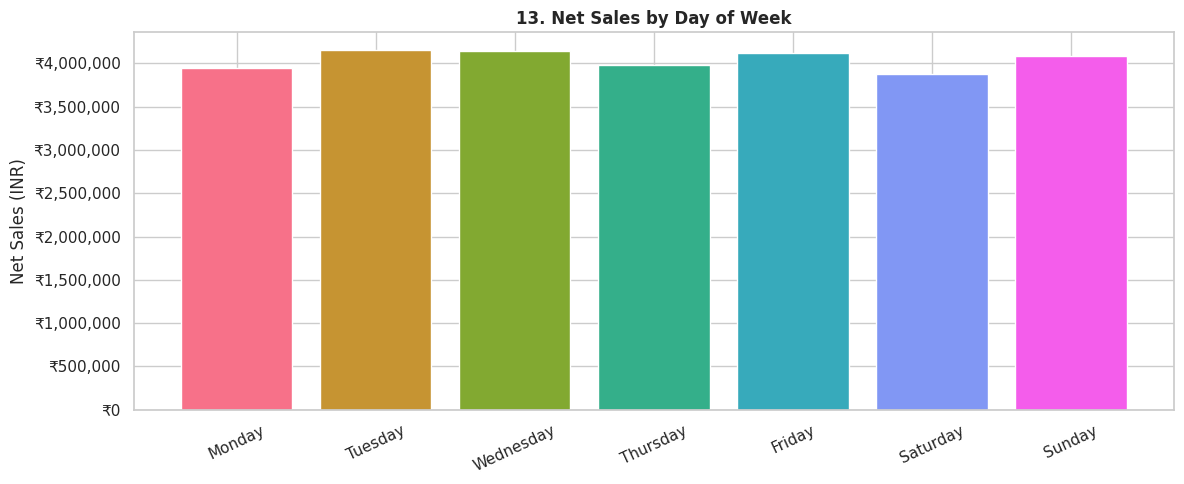

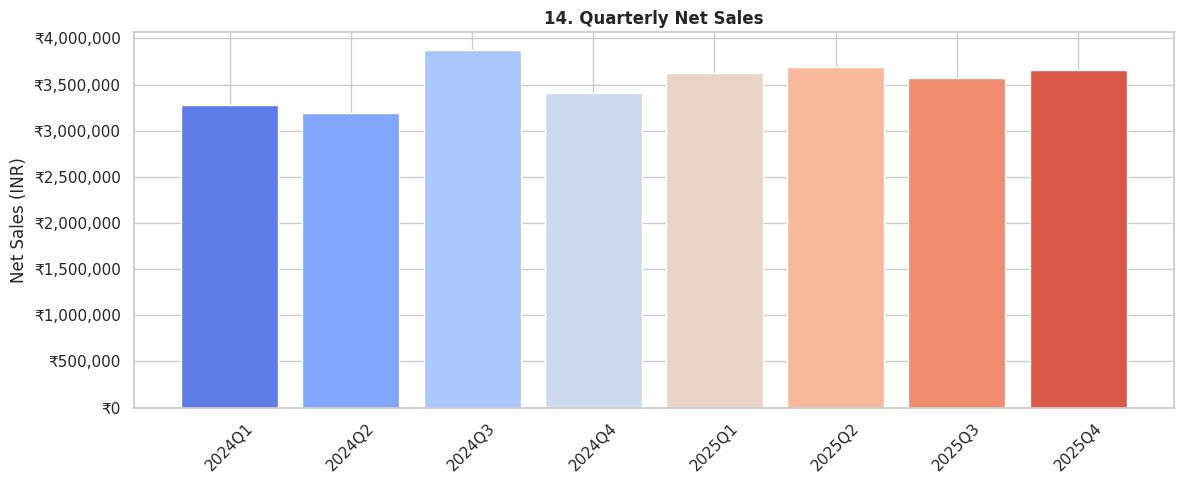

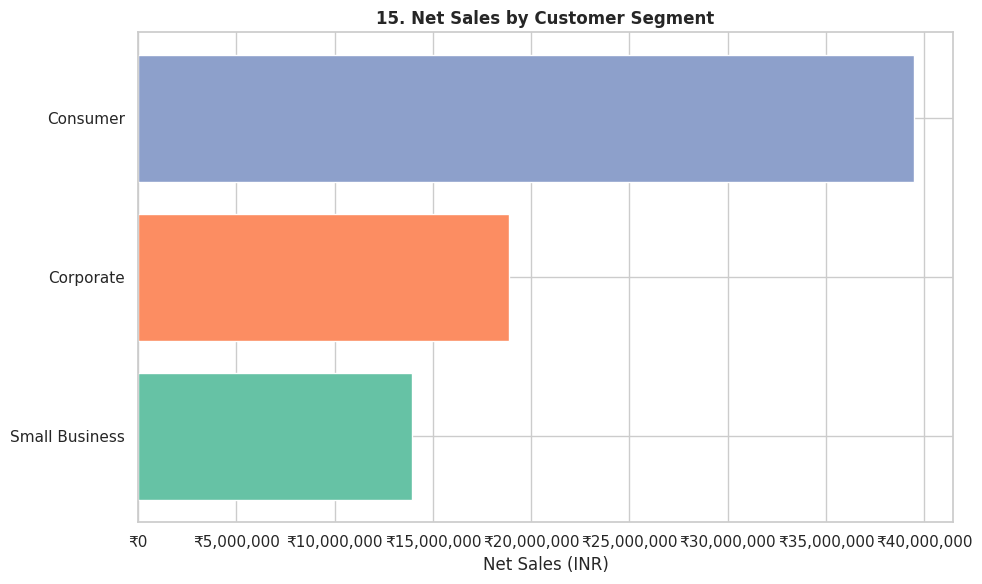

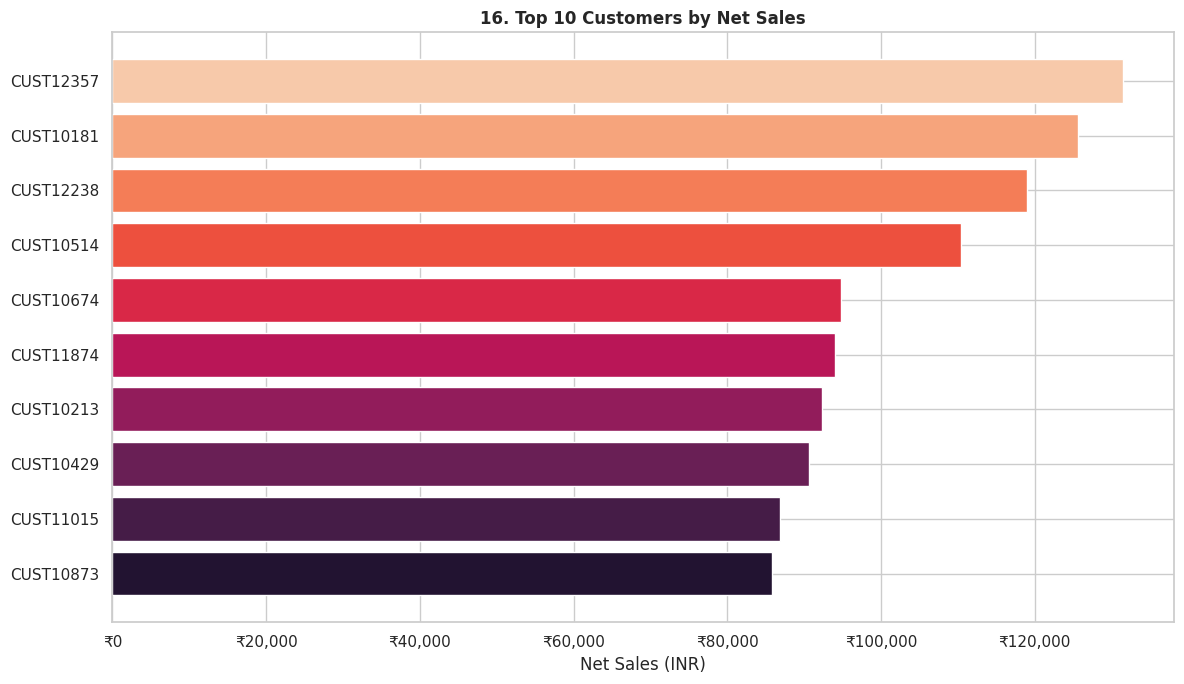

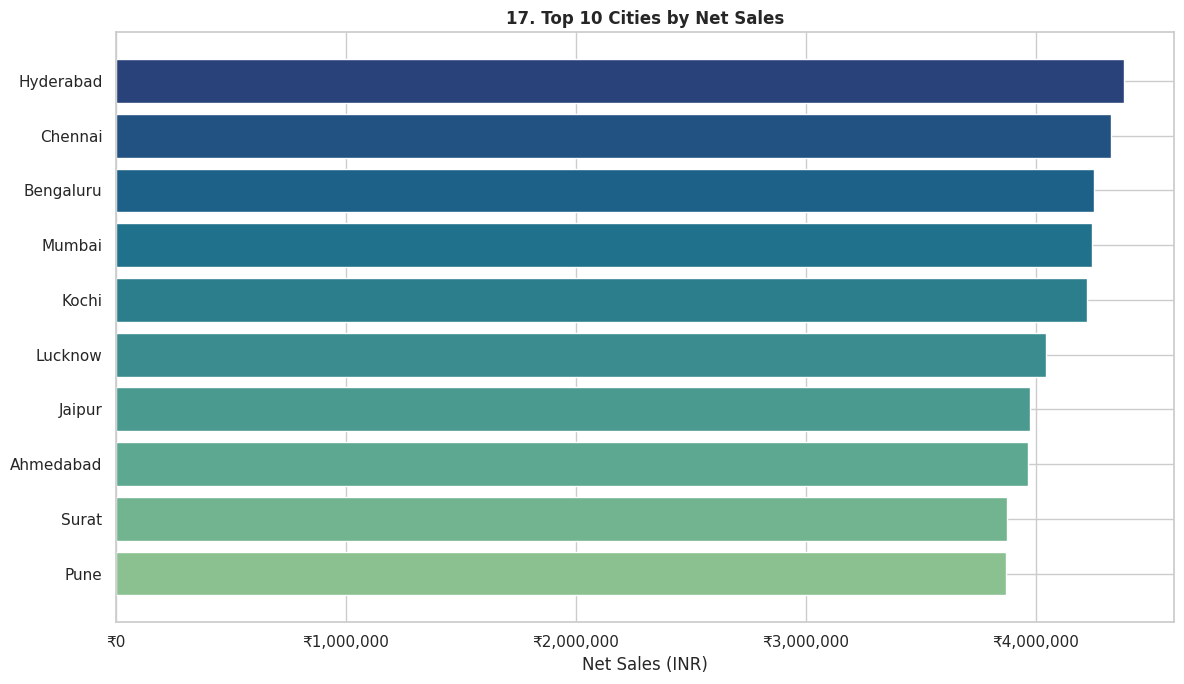

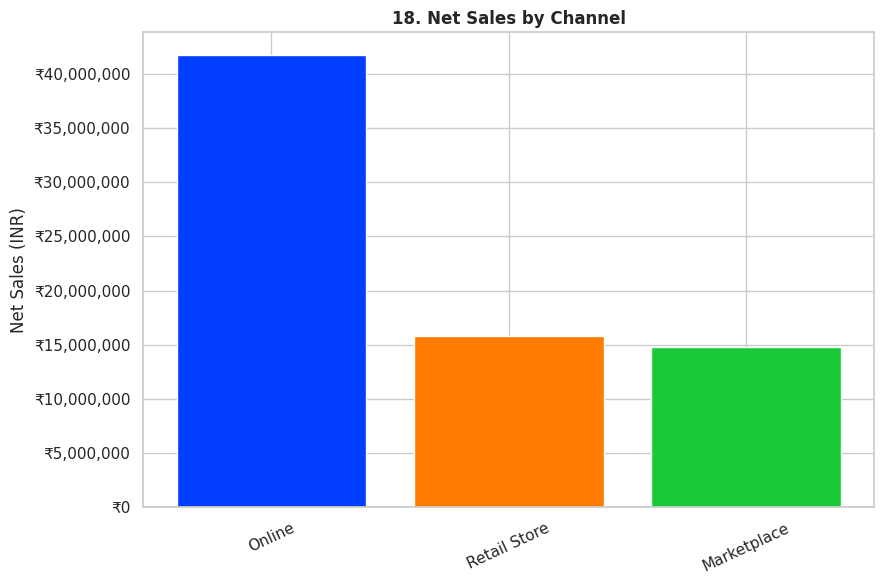

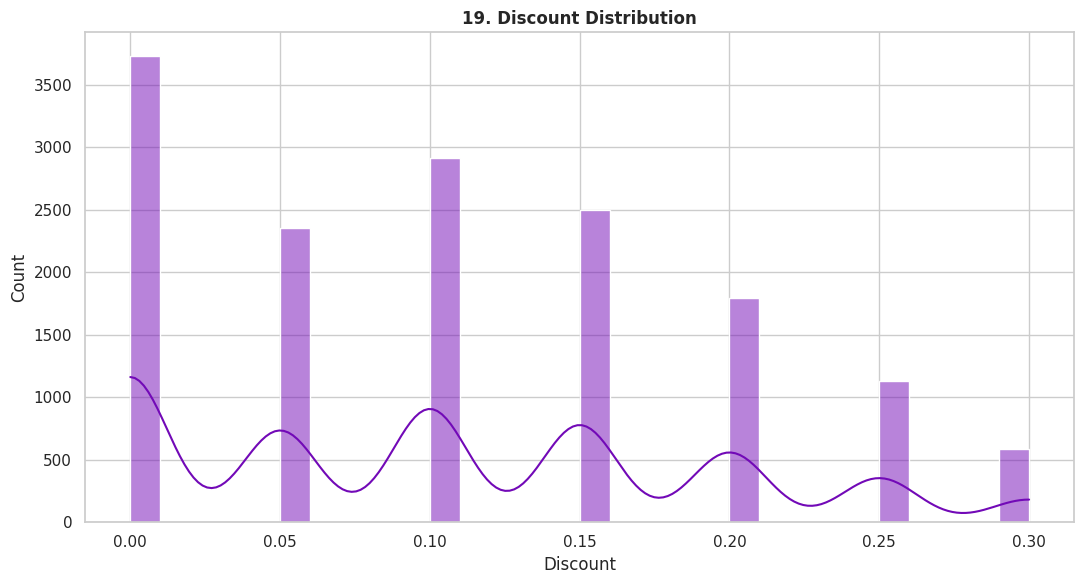

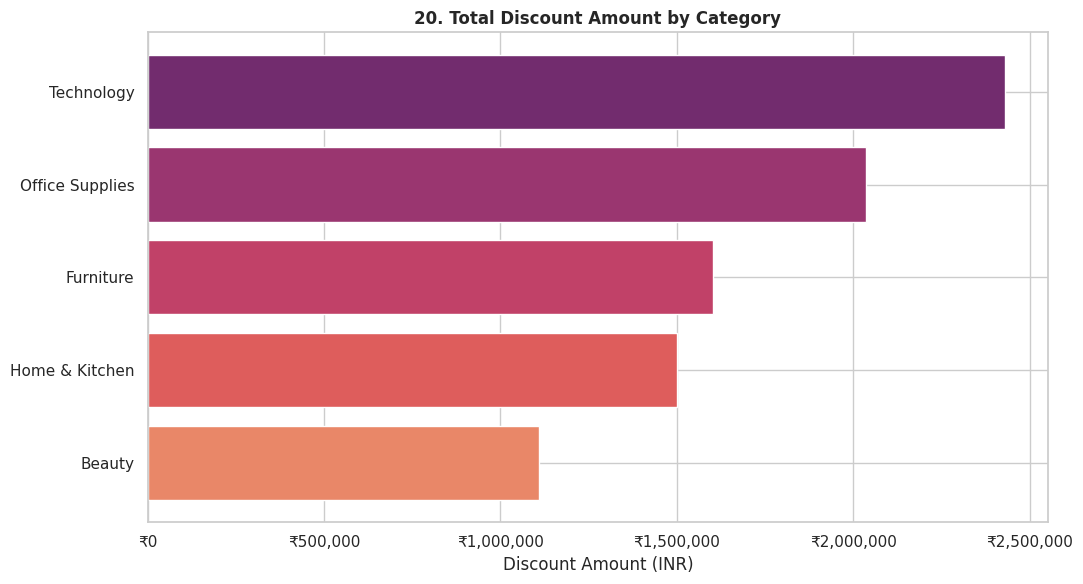

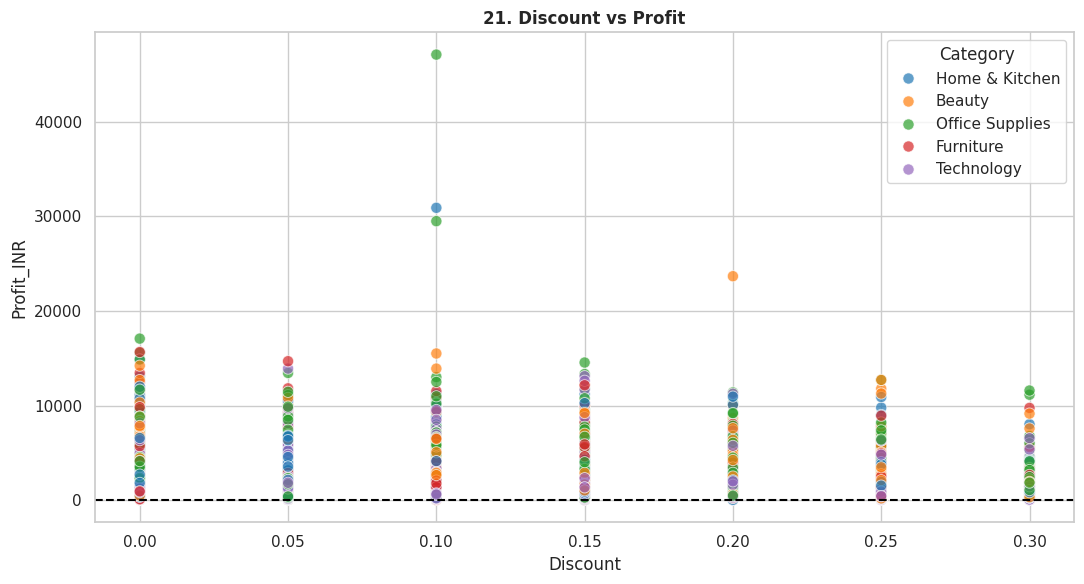

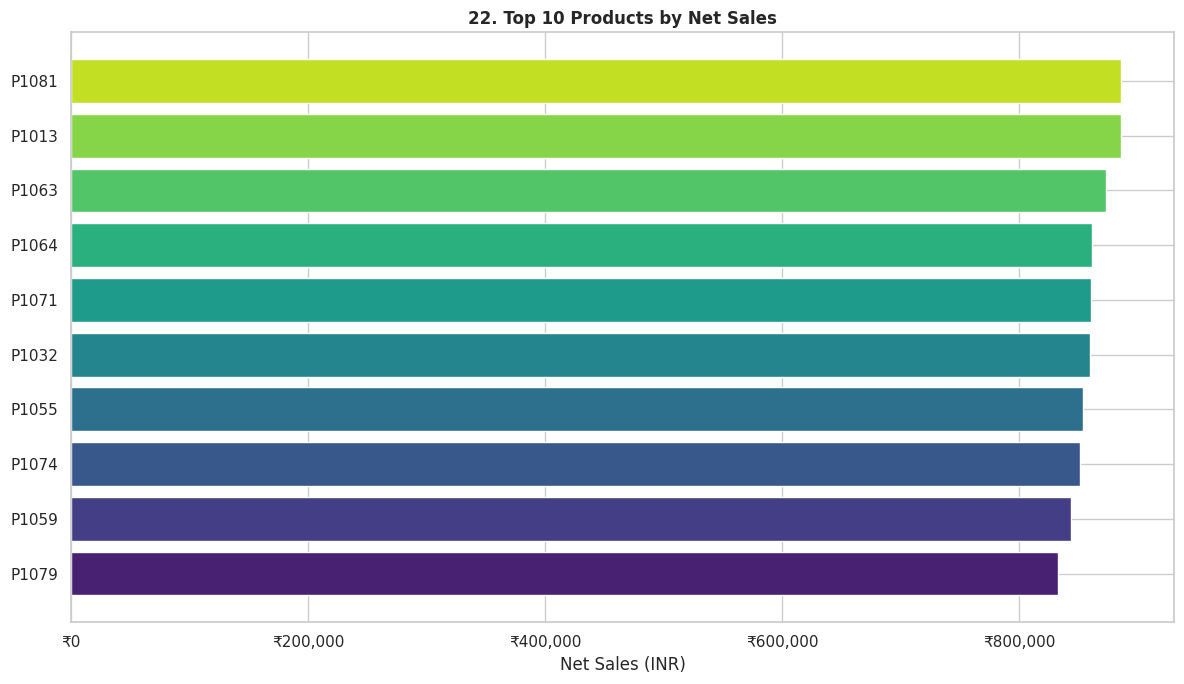

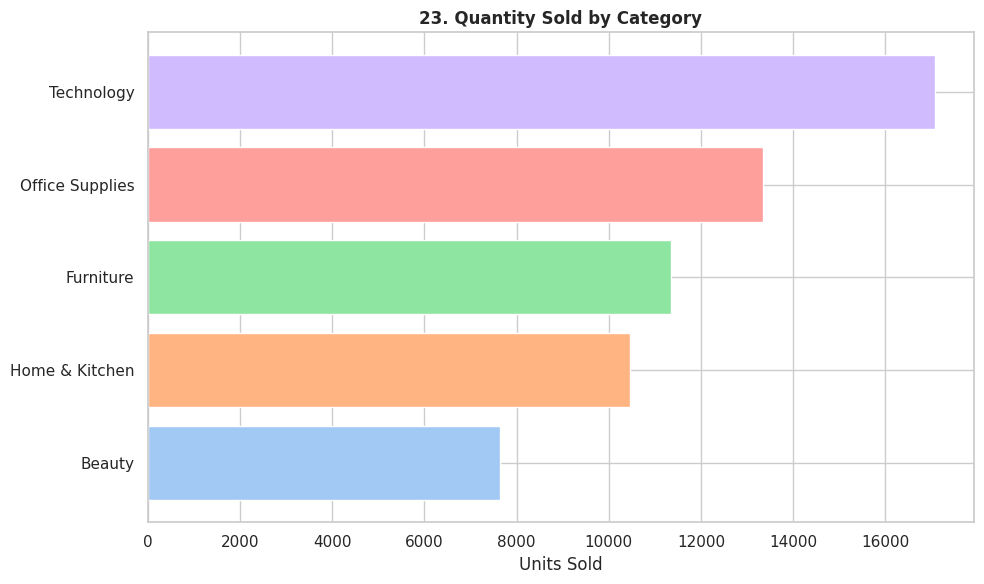

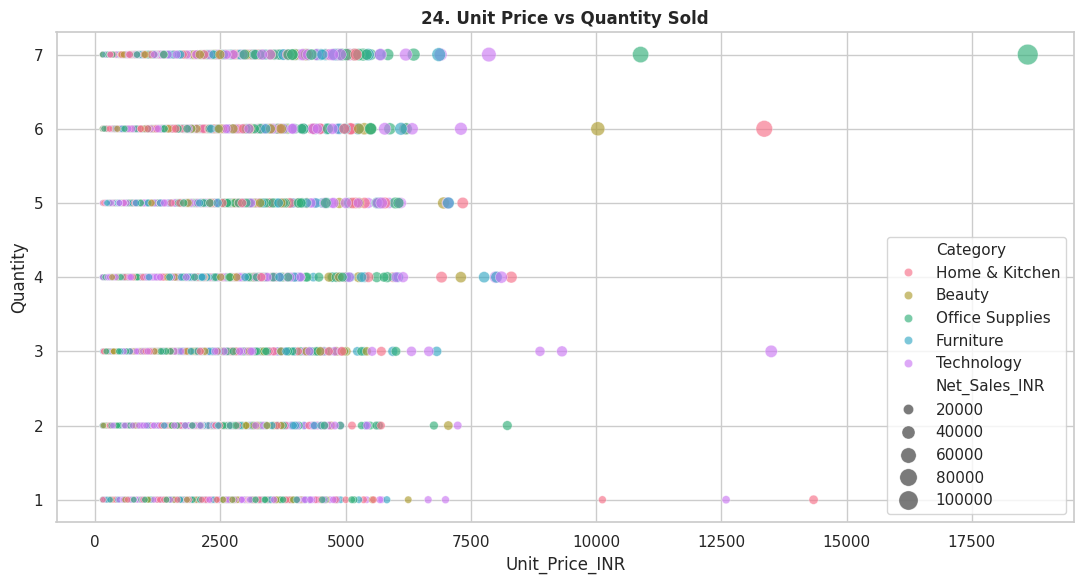

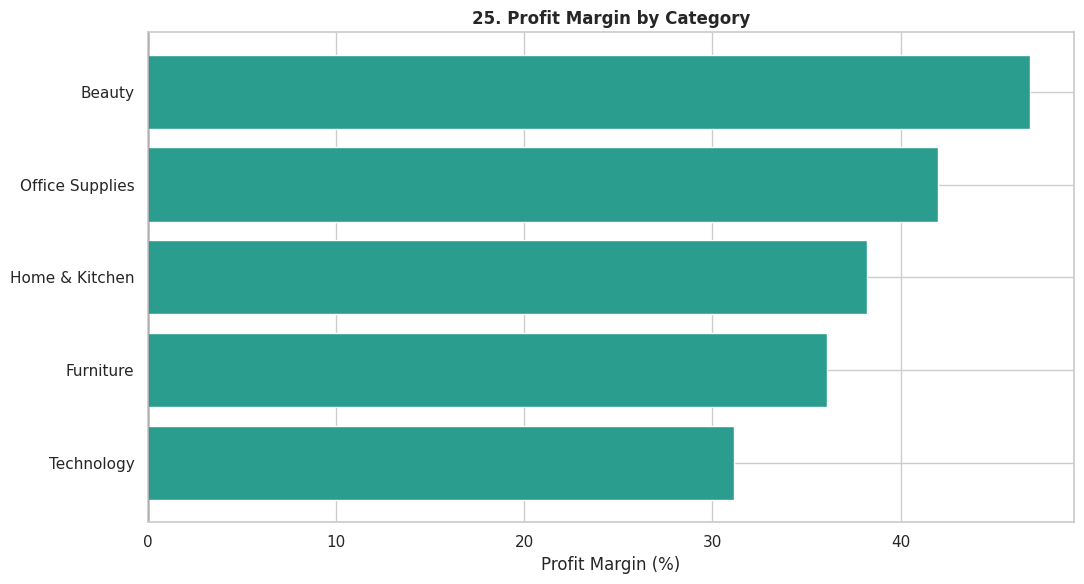

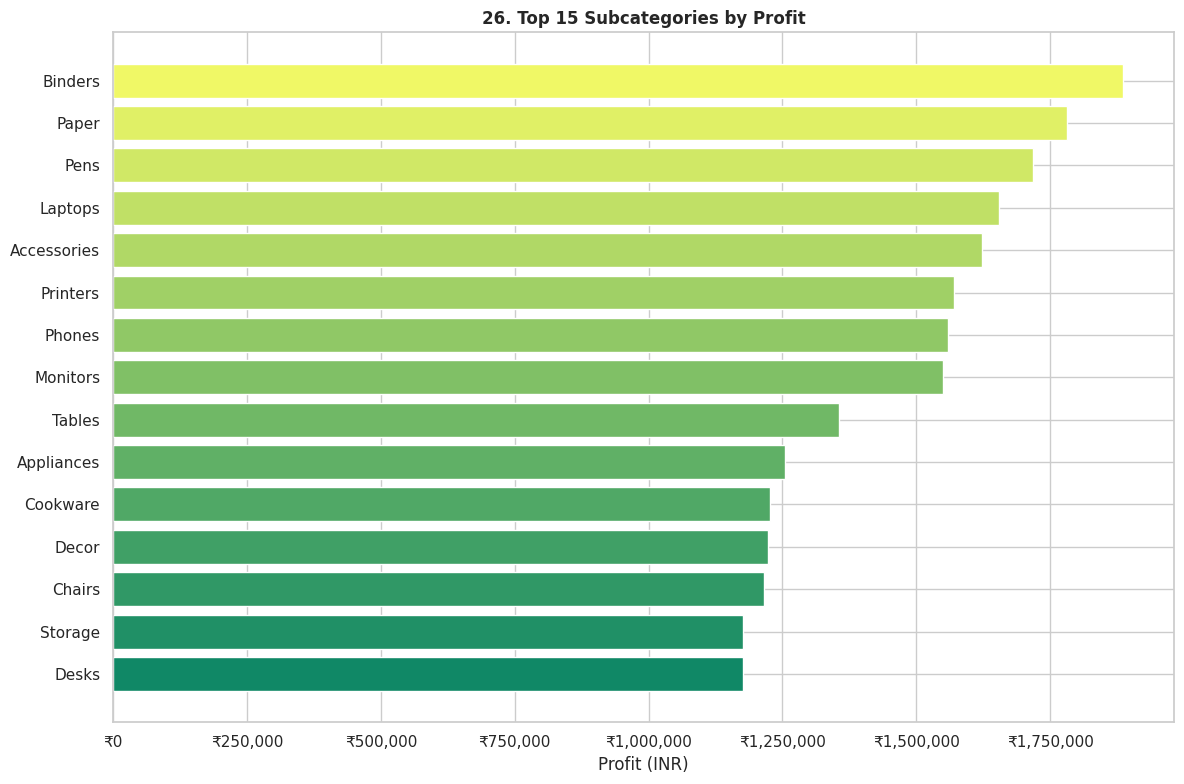

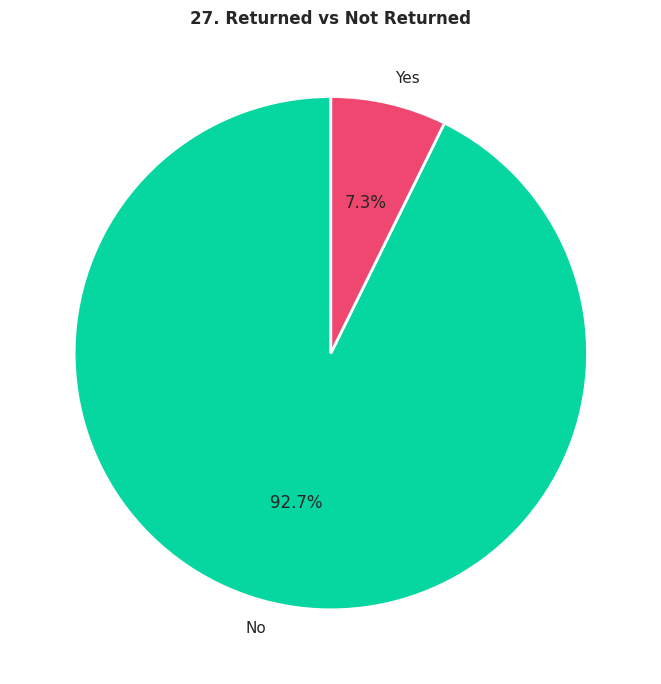

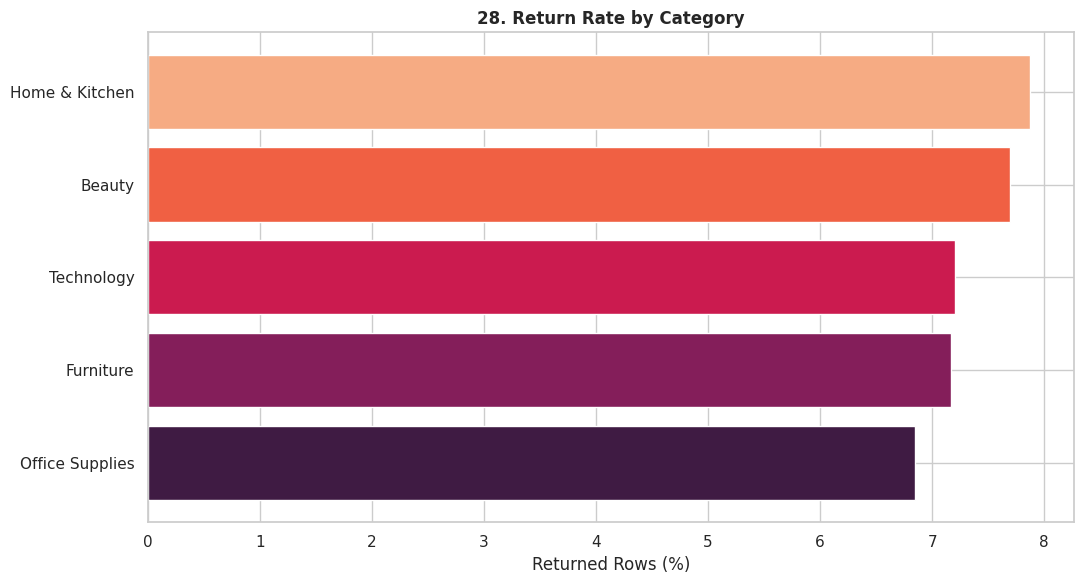

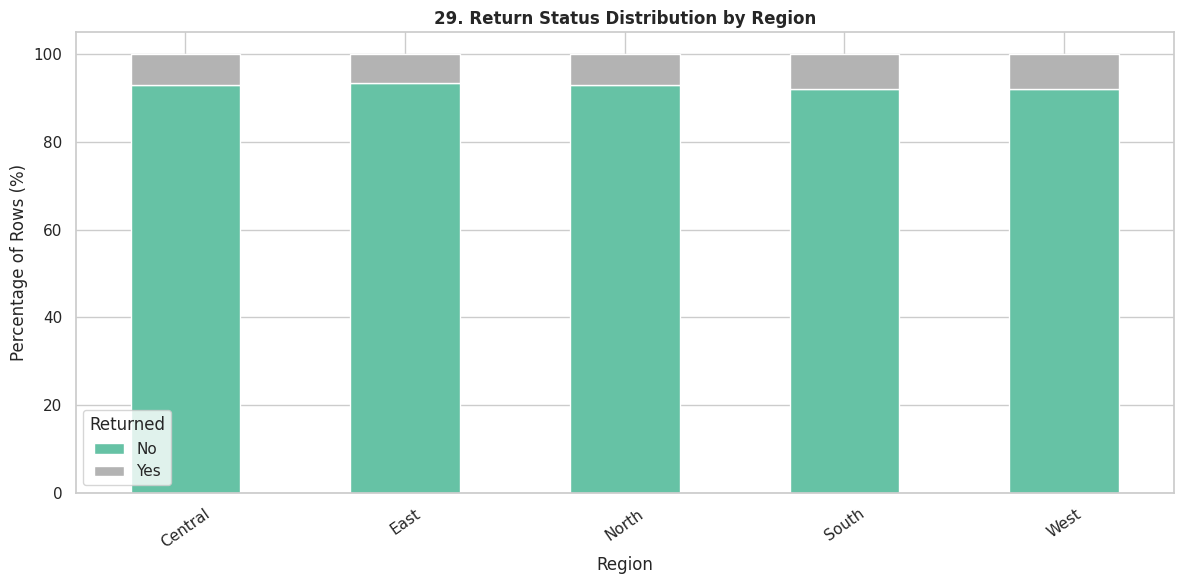

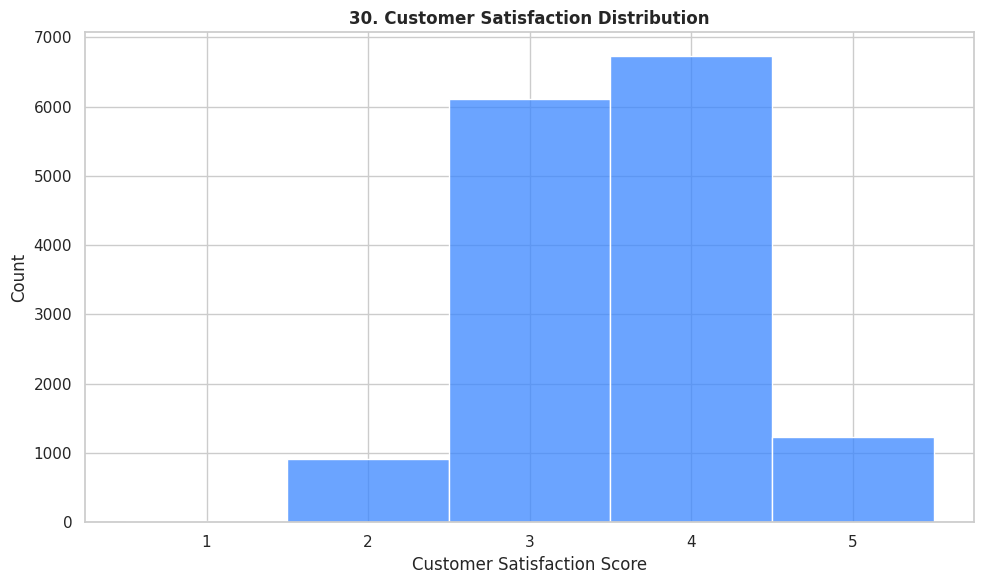

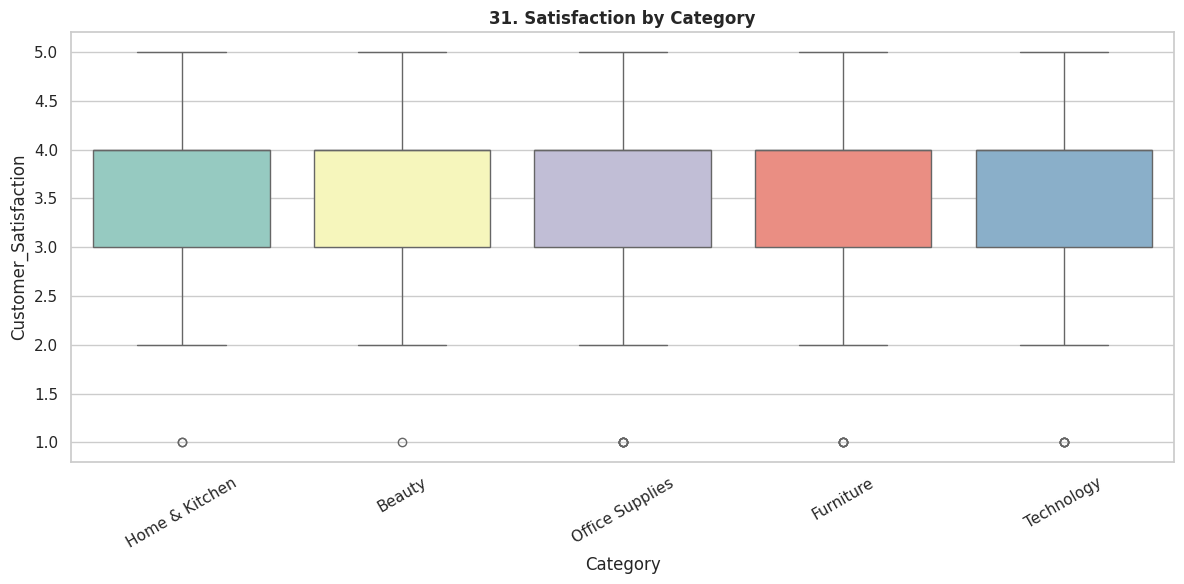

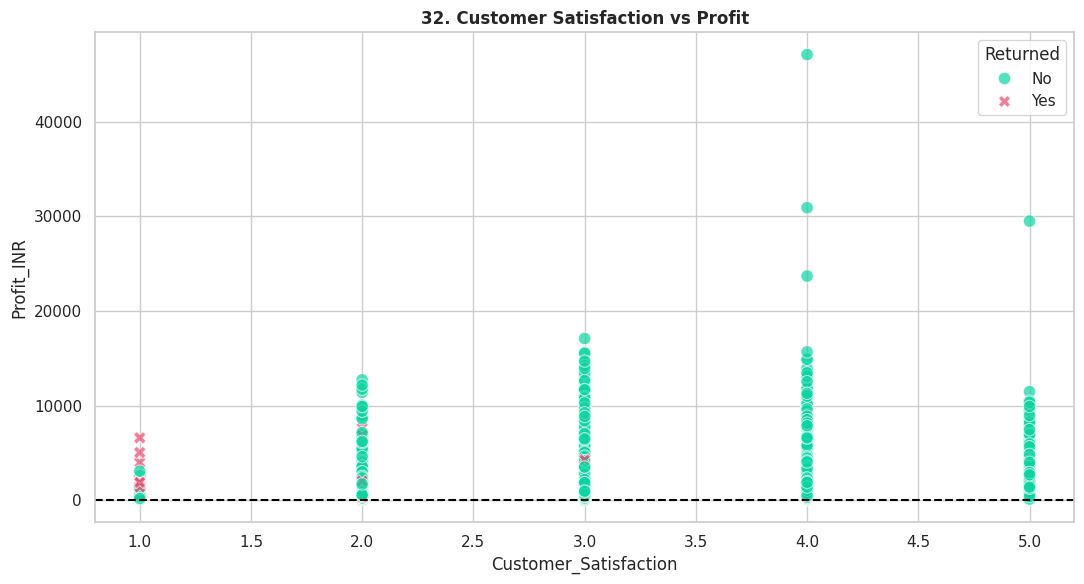

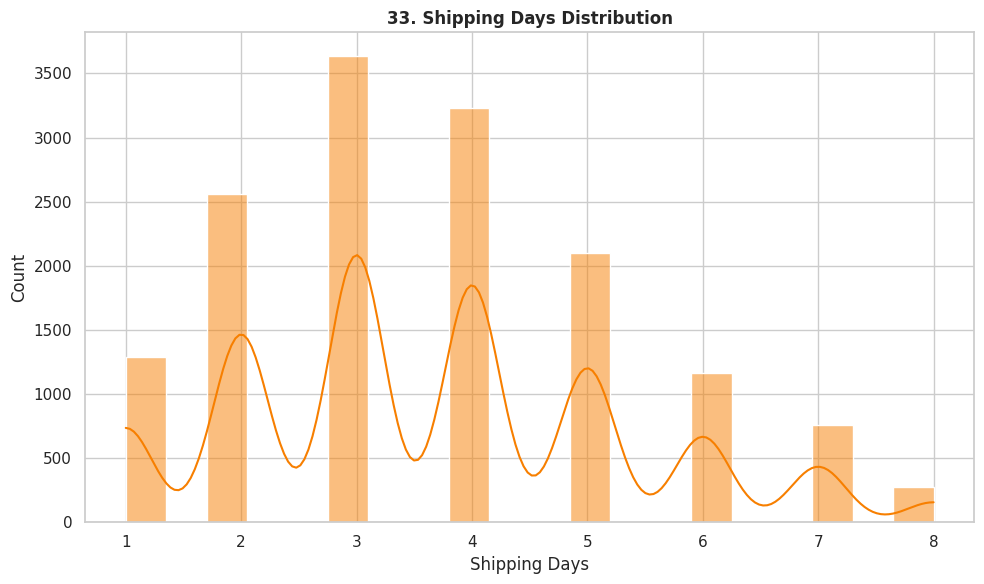

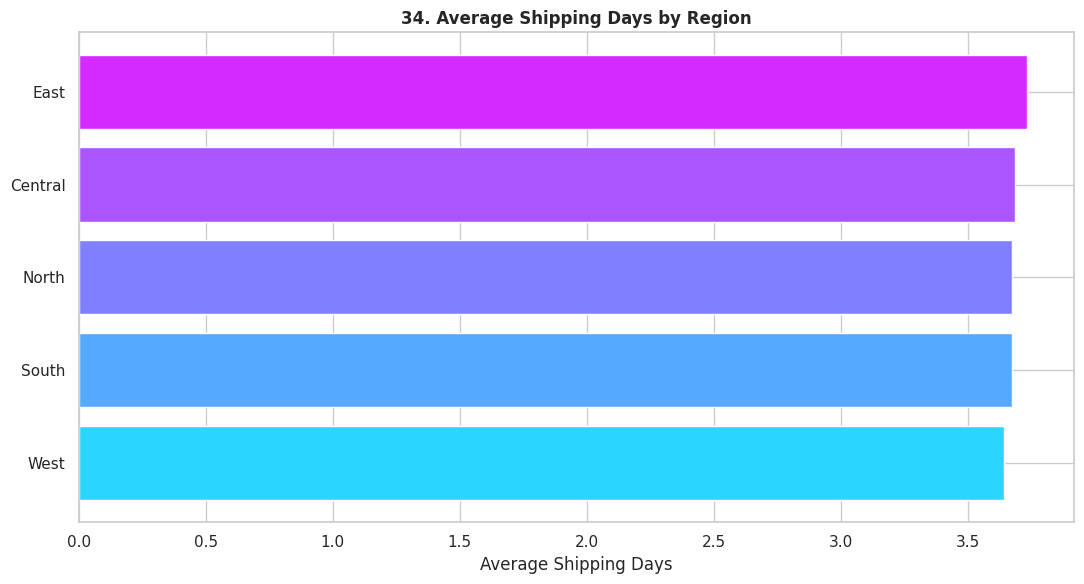

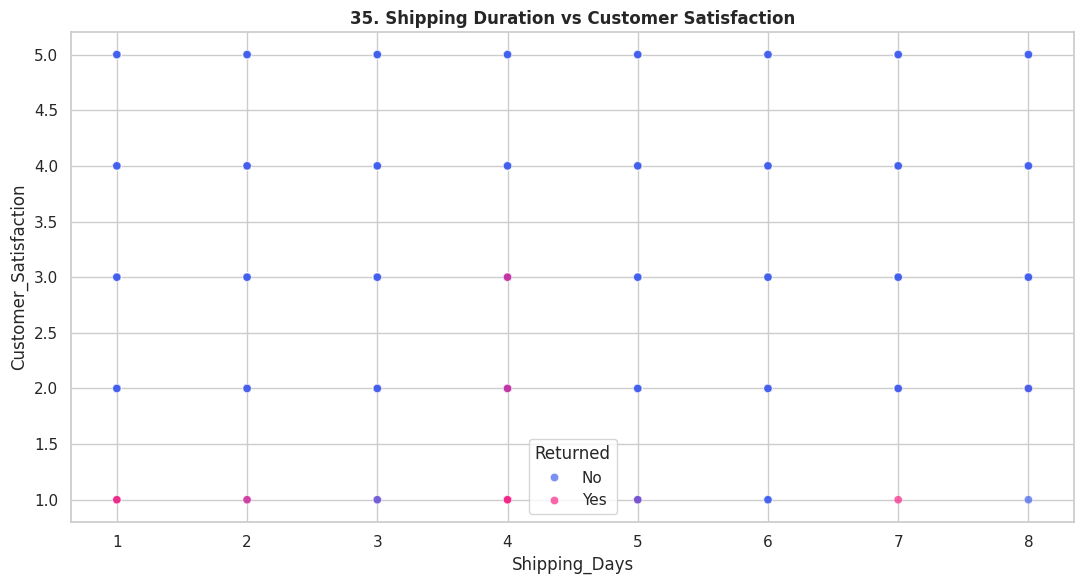

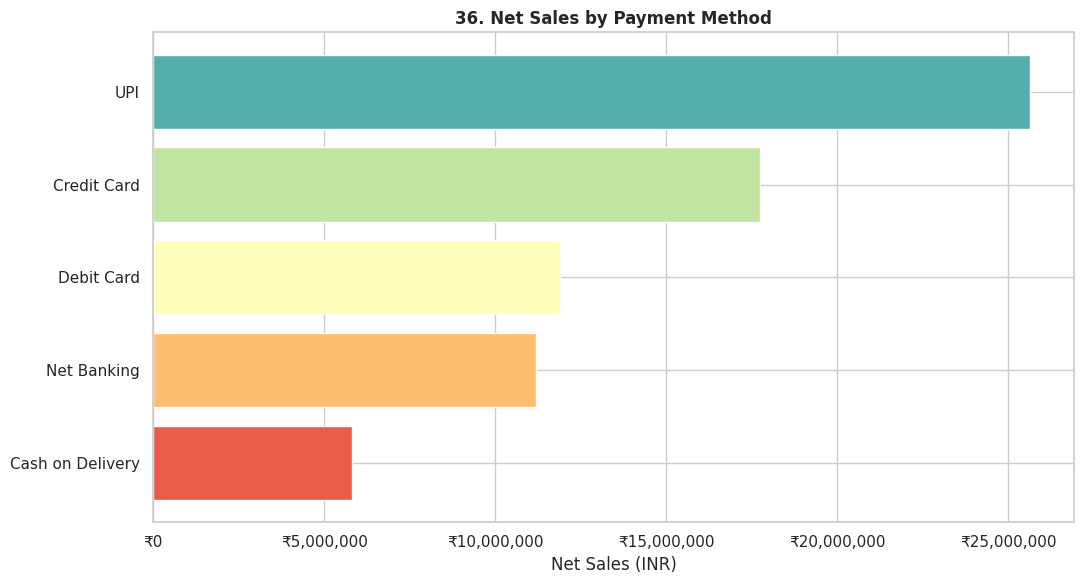

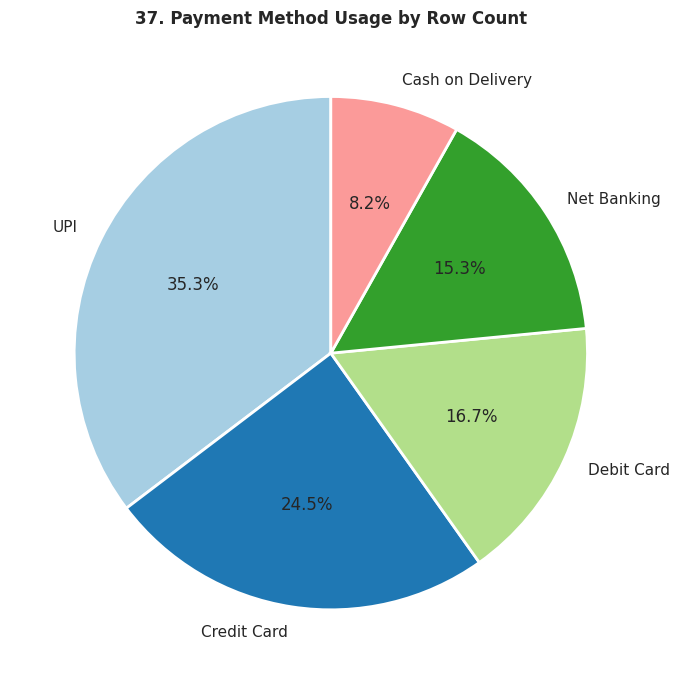

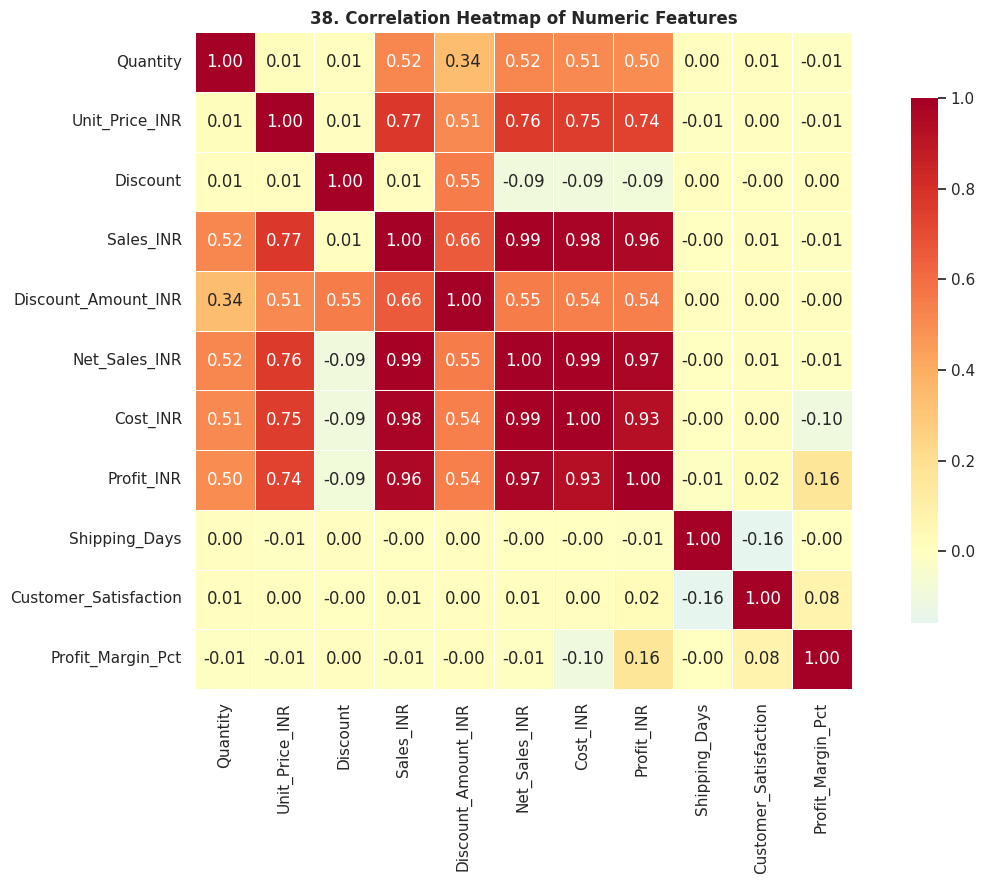


FINAL BUSINESS INSIGHTS SUMMARY
Top region by net sales: South (₹17,181,509.17)
Top category by net sales: Technology (₹20,491,207.69)
Top subcategory by net sales: Laptops (₹5,302,434.56)
Most profitable region: South (₹6,461,153.66)
Highest-spending customer: CUST12357 (₹131,548.56)
Leading payment method by net sales: UPI
Best month by net sales: 2025-03 (₹1,456,179.75)
Return rate (row-based): 7.30%
Average customer satisfaction: 3.55
Average shipping time: 3.68 days

Visualization project completed successfully!


In [13]:

# ================================================================
# COMPLETE SALES DATASET VISUALIZATION PROJECT
# Colorful EDA | Business Analytics | 30+ Visualization Charts
# Libraries: Pandas, NumPy, Matplotlib, Seaborn, Plotly
# Dataset DataFrame: df
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import FuncFormatter
from IPython.display import display

# Install Plotly automatically if required
try:
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
except ImportError:
    %pip install -q plotly
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

# -------------------- 1. SETTINGS --------------------

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.dpi"] = 100

PALETTE = [
    "#4361EE", "#F72585", "#4CC9F0", "#7209B7",
    "#F77F00", "#2A9D8F", "#E63946", "#FFBE0B",
    "#8338EC", "#06D6A0", "#FB5607", "#3A86FF"
]

if "df" not in globals():
    raise NameError("Please load your dataset into a DataFrame named df first.")

df = df.copy()

# -------------------- 2. DATA CLEANING --------------------

df.columns = df.columns.str.strip()

required_cols = [
    "Order_ID", "Order_Date", "Customer_ID", "Region", "City",
    "Segment", "Channel", "Category", "Subcategory", "Product_ID",
    "Quantity", "Unit_Price_INR", "Discount", "Sales_INR",
    "Discount_Amount_INR", "Net_Sales_INR", "Cost_INR", "Profit_INR",
    "Shipping_Days", "Returned", "Customer_Satisfaction", "Payment_Method"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing columns in df: {missing_cols}")

# Convert dates
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce",
                                  dayfirst=True)

# Convert numeric columns safely
numeric_cols = [
    "Quantity", "Unit_Price_INR", "Discount", "Sales_INR",
    "Discount_Amount_INR", "Net_Sales_INR", "Cost_INR", "Profit_INR",
    "Shipping_Days", "Customer_Satisfaction"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Normalize returned values
df["Returned"] = (
    df["Returned"].astype("string").str.strip().str.lower()
    .replace({
        "yes": "Yes", "y": "Yes", "true": "Yes", "1": "Yes",
        "no": "No", "n": "No", "false": "No", "0": "No"
    })
)

# Derived date columns
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%b")
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype("string")
df["Quarter"] = df["Order_Date"].dt.to_period("Q").astype("string")
df["Weekday"] = df["Order_Date"].dt.day_name()

# Normalize text dimensions
categorical_cols = [
    "Region", "City", "Segment", "Channel", "Category",
    "Subcategory", "Payment_Method"
]

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown").astype(str).str.strip()

# Additional business metrics
df["Profit_Margin_Pct"] = np.where(
    df["Net_Sales_INR"].notna() & (df["Net_Sales_INR"] != 0),
    df["Profit_INR"] / df["Net_Sales_INR"] * 100,
    np.nan
)

df["Average_Order_Value_INR"] = np.nan
valid_order_sales = df.dropna(subset=["Order_ID", "Net_Sales_INR"])
order_totals = valid_order_sales.groupby("Order_ID")["Net_Sales_INR"].sum()
df["Average_Order_Value_INR"] = df["Order_ID"].map(order_totals)

# Use a consistent display format
def inr_format(x, pos=None):
    return f"₹{x:,.0f}"

print("=" * 75)
print("SALES DATASET: EXPLORATORY DATA ANALYSIS")
print("=" * 75)

print(f"Rows: {len(df):,}")
print(f"Columns after feature engineering: {df.shape[1]}")
print(f"Unique orders: {df['Order_ID'].nunique():,}")
print(f"Unique customers: {df['Customer_ID'].nunique():,}")
print(f"Unique products: {df['Product_ID'].nunique():,}")
print(f"Date range: {df['Order_Date'].min()} to {df['Order_Date'].max()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print("\nMissing values in original columns:")
display(df[required_cols].isna().sum().to_frame("Missing_Count"))

# -------------------- 3. KPI SUMMARY --------------------

total_sales = df["Sales_INR"].sum()
net_sales = df["Net_Sales_INR"].sum()
total_profit = df["Profit_INR"].sum()
total_cost = df["Cost_INR"].sum()
total_discount = df["Discount_Amount_INR"].sum()
total_quantity = df["Quantity"].sum()
avg_satisfaction = df["Customer_Satisfaction"].mean()
avg_shipping = df["Shipping_Days"].mean()

order_level = df.groupby("Order_ID", dropna=True).agg(
    Order_Net_Sales=("Net_Sales_INR", "sum"),
    Order_Profit=("Profit_INR", "sum")
)

avg_order_value = order_level["Order_Net_Sales"].mean()
unique_customers = df["Customer_ID"].nunique()
unique_orders = df["Order_ID"].nunique()

returned_mask = df["Returned"].eq("Yes")
return_rate = returned_mask.mean() * 100 if len(df) else np.nan

kpis = pd.DataFrame({
    "Metric": [
        "Gross Sales", "Net Sales", "Total Profit", "Total Cost",
        "Total Discount", "Units Sold", "Unique Orders",
        "Unique Customers", "Average Order Value", "Profit Margin %",
        "Return Rate %", "Average Customer Satisfaction",
        "Average Shipping Days"
    ],
    "Value": [
        total_sales, net_sales, total_profit, total_cost,
        total_discount, total_quantity, unique_orders,
        unique_customers, avg_order_value,
        total_profit / net_sales * 100 if net_sales else np.nan,
        return_rate, avg_satisfaction, avg_shipping
    ]
})

print("\nKEY PERFORMANCE INDICATORS")
display(kpis.round(2))

# -------------------- 4. BASIC DATA VISUALIZATIONS --------------------

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

# 1. Dataset missing values
missing = df[required_cols].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing):
    axes[0, 0].bar(missing.index, missing.values, color=PALETTE[:len(missing)])
    axes[0, 0].tick_params(axis="x", rotation=70)
    axes[0, 0].set_title("1. Missing Values by Column")
    axes[0, 0].set_ylabel("Missing rows")
else:
    axes[0, 0].text(0.5, 0.5, "No missing values in original columns",
                    ha="center", va="center")
    axes[0, 0].set_title("1. Missing Values")

# 2. Sales, profit and costs
metric_values = [total_sales, net_sales, total_profit, total_cost, total_discount]
metric_labels = ["Gross Sales", "Net Sales", "Profit", "Cost", "Discount"]
axes[0, 1].bar(metric_labels, metric_values,
               color=PALETTE[:5], edgecolor="white")
axes[0, 1].set_title("2. Financial Overview (INR)")
axes[0, 1].yaxis.set_major_formatter(FuncFormatter(inr_format))
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Quantity distribution
sns.histplot(df["Quantity"].dropna(), bins=30, kde=True,
             color="#4361EE", ax=axes[1, 0])
axes[1, 0].set_title("3. Quantity Distribution")

# 4. Profit distribution
sns.histplot(df["Profit_INR"].dropna(), bins=40, kde=True,
             color="#F72585", ax=axes[1, 1])
axes[1, 1].axvline(0, color="black", linestyle="--")
axes[1, 1].set_title("4. Profit Distribution")

plt.tight_layout()
plt.show()

# -------------------- 5. SALES BY REGION --------------------

region_sales = (
    df.groupby("Region", dropna=False)["Net_Sales_INR"]
    .sum().sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=region_sales.index, y=region_sales.values,
            hue=region_sales.index, palette="viridis", legend=False)
plt.title("5. Net Sales by Region")
plt.xlabel("Region")
plt.ylabel("Net Sales (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 6. Profit by region
region_profit = (
    df.groupby("Region")["Profit_INR"].sum().sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
colors = ["#06D6A0" if x >= 0 else "#EF476F" for x in region_profit.values]
plt.bar(region_profit.index, region_profit.values, color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.title("6. Profit and Loss by Region")
plt.ylabel("Profit (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# -------------------- 6. CATEGORY AND SUBCATEGORY --------------------

category_sales = (
    df.groupby("Category")["Net_Sales_INR"]
    .sum().sort_values(ascending=False)
)

# 7. Category sales pie chart
plt.figure(figsize=(9, 8))
plt.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set3", len(category_sales)),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
plt.title("7. Sales Contribution by Category")
plt.tight_layout()
plt.show()

# 8. Subcategory sales
subcategory_sales = (
    df.groupby("Subcategory")["Net_Sales_INR"]
    .sum().nlargest(15).sort_values()
)

plt.figure(figsize=(12, 8))
plt.barh(subcategory_sales.index, subcategory_sales.values,
         color=sns.color_palette("magma", len(subcategory_sales)))
plt.title("8. Top 15 Subcategories by Net Sales")
plt.xlabel("Net Sales (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 9. Sales versus profit by category
cat_finance = df.groupby("Category")[["Net_Sales_INR", "Profit_INR"]].sum()

cat_finance.plot(kind="bar", figsize=(13, 6),
                 color=["#4361EE", "#F72585"], edgecolor="white")
plt.title("9. Net Sales vs Profit by Category")
plt.ylabel("INR")
plt.xticks(rotation=30)
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# -------------------- 7. MONTHLY AND TIME TRENDS --------------------

monthly = (
    df.dropna(subset=["Order_Date"])
    .set_index("Order_Date")
    .resample("MS")
    .agg(
        Net_Sales_INR=("Net_Sales_INR", "sum"),
        Profit_INR=("Profit_INR", "sum"),
        Quantity=("Quantity", "sum"),
        Order_Count=("Order_ID", "nunique")
    )
)

# 10. Monthly net sales trend
plt.figure(figsize=(15, 6))
plt.plot(monthly.index, monthly["Net_Sales_INR"],
         marker="o", linewidth=2.5, color="#4361EE")
plt.fill_between(monthly.index, monthly["Net_Sales_INR"],
                 alpha=0.18, color="#4361EE")
plt.title("10. Monthly Net Sales Trend")
plt.ylabel("Net Sales (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 11. Monthly profit trend
plt.figure(figsize=(15, 6))
plt.plot(monthly.index, monthly["Profit_INR"],
         marker="D", color="#F72585", linewidth=2)
plt.axhline(0, color="black", linestyle="--")
plt.title("11. Monthly Profit Trend")
plt.ylabel("Profit (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 12. Monthly sales and profit comparison
fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.plot(monthly.index, monthly["Net_Sales_INR"],
         color="#4361EE", marker="o", label="Net Sales")
ax1.set_ylabel("Net Sales (INR)", color="#4361EE")
ax1.yaxis.set_major_formatter(FuncFormatter(inr_format))
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["Profit_INR"],
         color="#F72585", marker="s", label="Profit")
ax2.set_ylabel("Profit (INR)", color="#F72585")
ax1.set_title("12. Monthly Net Sales and Profit")
ax1.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

# 13. Sales by weekday
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
weekday_sales = (
    df.groupby("Weekday")["Net_Sales_INR"].sum()
    .reindex(weekday_order)
)

plt.figure(figsize=(12, 5))
plt.bar(weekday_sales.index, weekday_sales.values,
        color=sns.color_palette("husl", 7))
plt.title("13. Net Sales by Day of Week")
plt.ylabel("Net Sales (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 14. Quarterly sales
quarter_sales = df.groupby("Quarter")["Net_Sales_INR"].sum()

plt.figure(figsize=(12, 5))
plt.bar(quarter_sales.index, quarter_sales.values,
        color=sns.color_palette("coolwarm", len(quarter_sales)))
plt.title("14. Quarterly Net Sales")
plt.ylabel("Net Sales (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -------------------- 8. CUSTOMER AND SEGMENT ANALYSIS --------------------

# 15. Sales by customer segment
segment_sales = df.groupby("Segment")["Net_Sales_INR"].sum().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(segment_sales.index, segment_sales.values,
         color=sns.color_palette("Set2", len(segment_sales)))
plt.title("15. Net Sales by Customer Segment")
plt.xlabel("Net Sales (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 16. Top 10 customers
customer_sales = (
    df.groupby("Customer_ID")["Net_Sales_INR"]
    .sum().nlargest(10).sort_values()
)

plt.figure(figsize=(12, 7))
plt.barh(customer_sales.index.astype(str), customer_sales.values,
         color=sns.color_palette("rocket", len(customer_sales)))
plt.title("16. Top 10 Customers by Net Sales")
plt.xlabel("Net Sales (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 17. Top 10 cities
city_sales = df.groupby("City")["Net_Sales_INR"].sum().nlargest(10).sort_values()

plt.figure(figsize=(12, 7))
plt.barh(city_sales.index, city_sales.values,
         color=sns.color_palette("crest", len(city_sales)))
plt.title("17. Top 10 Cities by Net Sales")
plt.xlabel("Net Sales (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 18. Sales by channel
channel_sales = df.groupby("Channel")["Net_Sales_INR"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 6))
plt.bar(channel_sales.index, channel_sales.values,
        color=sns.color_palette("bright", len(channel_sales)))
plt.title("18. Net Sales by Channel")
plt.ylabel("Net Sales (INR)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(inr_format))
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# -------------------- 9. DISCOUNT ANALYSIS --------------------

# 19. Discount distribution
plt.figure(figsize=(11, 6))
sns.histplot(df["Discount"].dropna(), bins=30, kde=True,
             color="#7209B7")
plt.title("19. Discount Distribution")
plt.xlabel("Discount")
plt.tight_layout()
plt.show()

# 20. Discount amount by category
discount_category = (
    df.groupby("Category")["Discount_Amount_INR"].sum().sort_values()
)

plt.figure(figsize=(11, 6))
plt.barh(discount_category.index, discount_category.values,
         color=sns.color_palette("flare", len(discount_category)))
plt.title("20. Total Discount Amount by Category")
plt.xlabel("Discount Amount (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 21. Discount versus profit
discount_profit = df.dropna(subset=["Discount", "Profit_INR"])

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=discount_profit,
    x="Discount", y="Profit_INR",
    hue="Category", palette="tab10",
    alpha=0.7, s=65
)
plt.axhline(0, color="black", linestyle="--")
plt.title("21. Discount vs Profit")
plt.tight_layout()
plt.show()

# -------------------- 10. PRODUCT AND QUANTITY ANALYSIS --------------------

# 22. Top 10 products by sales
product_sales = (
    df.groupby("Product_ID")["Net_Sales_INR"]
    .sum().nlargest(10).sort_values()
)

plt.figure(figsize=(12, 7))
plt.barh(product_sales.index.astype(str), product_sales.values,
         color=sns.color_palette("viridis", len(product_sales)))
plt.title("22. Top 10 Products by Net Sales")
plt.xlabel("Net Sales (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 23. Quantity sold by category
category_quantity = df.groupby("Category")["Quantity"].sum().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(category_quantity.index, category_quantity.values,
         color=sns.color_palette("pastel", len(category_quantity)))
plt.title("23. Quantity Sold by Category")
plt.xlabel("Units Sold")
plt.tight_layout()
plt.show()

# 24. Unit price versus quantity
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df, x="Unit_Price_INR", y="Quantity",
    hue="Category", size="Net_Sales_INR",
    sizes=(20, 220), alpha=0.65, palette="husl",
    legend="brief"
)
plt.title("24. Unit Price vs Quantity Sold")
plt.tight_layout()
plt.show()

# -------------------- 11. PROFITABILITY ANALYSIS --------------------

# 25. Profit margin by category
margin_category = (
    df.groupby("Category")
    .agg(Net_Sales=("Net_Sales_INR", "sum"),
         Profit=("Profit_INR", "sum"))
)
margin_category["Profit_Margin_Pct"] = np.where(
    margin_category["Net_Sales"] != 0,
    margin_category["Profit"] / margin_category["Net_Sales"] * 100,
    np.nan
)
margin_category = margin_category["Profit_Margin_Pct"].dropna().sort_values()

plt.figure(figsize=(11, 6))
colors = ["#E63946" if v < 0 else "#2A9D8F" for v in margin_category.values]
plt.barh(margin_category.index, margin_category.values, color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("25. Profit Margin by Category")
plt.xlabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

# 26. Top profitable subcategories
subcat_profit = (
    df.groupby("Subcategory")["Profit_INR"]
    .sum().nlargest(15).sort_values()
)

plt.figure(figsize=(12, 8))
plt.barh(subcat_profit.index, subcat_profit.values,
         color=sns.color_palette("summer", len(subcat_profit)))
plt.title("26. Top 15 Subcategories by Profit")
plt.xlabel("Profit (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# -------------------- 12. RETURNS ANALYSIS --------------------

return_counts = df["Returned"].value_counts(dropna=False)

# 27. Returned vs not returned
plt.figure(figsize=(8, 7))
plt.pie(
    return_counts.values,
    labels=return_counts.index.astype(str),
    autopct="%1.1f%%", startangle=90,
    colors=["#06D6A0", "#EF476F", "#ADB5BD"][:len(return_counts)],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
plt.title("27. Returned vs Not Returned")
plt.tight_layout()
plt.show()

# 28. Return rate by category
return_category = (
    df.assign(Return_Flag=df["Returned"].eq("Yes").astype(int))
    .groupby("Category")["Return_Flag"].mean().mul(100).sort_values()
)

plt.figure(figsize=(11, 6))
plt.barh(return_category.index, return_category.values,
         color=sns.color_palette("rocket", len(return_category)))
plt.title("28. Return Rate by Category")
plt.xlabel("Returned Rows (%)")
plt.tight_layout()
plt.show()

# 29. Returns by region
return_region = pd.crosstab(df["Region"], df["Returned"], normalize="index") * 100

return_region.plot(
    kind="bar", stacked=True, figsize=(12, 6),
    colormap="Set2", edgecolor="white"
)
plt.title("29. Return Status Distribution by Region")
plt.ylabel("Percentage of Rows (%)")
plt.xticks(rotation=35)
plt.legend(title="Returned")
plt.tight_layout()
plt.show()

# -------------------- 13. CUSTOMER SATISFACTION --------------------

# 30. Satisfaction distribution
plt.figure(figsize=(10, 6))
sns.histplot(
    df["Customer_Satisfaction"].dropna(),
    discrete=True, kde=False, color="#3A86FF"
)
plt.title("30. Customer Satisfaction Distribution")
plt.xlabel("Customer Satisfaction Score")
plt.tight_layout()
plt.show()

# 31. Satisfaction by category
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df, x="Category", y="Customer_Satisfaction",
    hue="Category", palette="Set3", legend=False
)
plt.title("31. Satisfaction by Category")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 32. Satisfaction versus profit
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df, x="Customer_Satisfaction", y="Profit_INR",
    hue="Returned", style="Returned",
    palette={"Yes": "#EF476F", "No": "#06D6A0"},
    alpha=0.7, s=80
)
plt.axhline(0, color="black", linestyle="--")
plt.title("32. Customer Satisfaction vs Profit")
plt.tight_layout()
plt.show()

# -------------------- 14. SHIPPING ANALYSIS --------------------

# 33. Shipping days distribution
plt.figure(figsize=(10, 6))
sns.histplot(df["Shipping_Days"].dropna(), bins=20,
             kde=True, color="#F77F00")
plt.title("33. Shipping Days Distribution")
plt.xlabel("Shipping Days")
plt.tight_layout()
plt.show()

# 34. Average shipping days by region
shipping_region = df.groupby("Region")["Shipping_Days"].mean().sort_values()

plt.figure(figsize=(11, 6))
plt.barh(shipping_region.index, shipping_region.values,
         color=sns.color_palette("cool", len(shipping_region)))
plt.title("34. Average Shipping Days by Region")
plt.xlabel("Average Shipping Days")
plt.tight_layout()
plt.show()

# 35. Shipping days vs satisfaction
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df, x="Shipping_Days", y="Customer_Satisfaction",
    hue="Returned", palette={"Yes": "#F72585", "No": "#4361EE"},
    alpha=0.7
)
plt.title("35. Shipping Duration vs Customer Satisfaction")
plt.tight_layout()
plt.show()

# -------------------- 15. PAYMENT ANALYSIS --------------------

payment_sales = df.groupby("Payment_Method")["Net_Sales_INR"].sum().sort_values()

# 36. Sales by payment method
plt.figure(figsize=(11, 6))
plt.barh(payment_sales.index, payment_sales.values,
         color=sns.color_palette("Spectral", len(payment_sales)))
plt.title("36. Net Sales by Payment Method")
plt.xlabel("Net Sales (INR)")
plt.gca().xaxis.set_major_formatter(FuncFormatter(inr_format))
plt.tight_layout()
plt.show()

# 37. Payment method usage
payment_counts = df["Payment_Method"].value_counts()

plt.figure(figsize=(9, 7))
plt.pie(
    payment_counts.values, labels=payment_counts.index,
    autopct="%1.1f%%", startangle=90,
    colors=sns.color_palette("Paired", len(payment_counts)),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
plt.title("37. Payment Method Usage by Row Count")
plt.tight_layout()
plt.show()

# -------------------- 16. CORRELATION HEATMAP --------------------

corr_cols = [
    "Quantity", "Unit_Price_INR", "Discount",
    "Sales_INR", "Discount_Amount_INR", "Net_Sales_INR",
    "Cost_INR", "Profit_INR", "Shipping_Days",
    "Customer_Satisfaction", "Profit_Margin_Pct"
]

corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(
    corr, annot=True, fmt=".2f",
    cmap="RdYlBu_r", center=0,
    linewidths=0.5, square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title("38. Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

# -------------------- 17. INTERACTIVE PLOTLY CHARTS --------------------

# Interactive charts have hover details and zoom controls.
# 39. Interactive sales by region
fig = px.bar(
    df.groupby("Region", as_index=False)["Net_Sales_INR"].sum(),
    x="Region", y="Net_Sales_INR",
    color="Region", color_discrete_sequence=px.colors.qualitative.Bold,
    title="39. Interactive Net Sales by Region",
    hover_data={"Net_Sales_INR": ":,.2f"}
)
fig.update_layout(showlegend=False, yaxis_tickprefix="₹")
fig.show()

# 40. Interactive monthly sales
interactive_monthly = monthly.reset_index()
fig = px.line(
    interactive_monthly, x="Order_Date", y="Net_Sales_INR",
    markers=True, title="40. Interactive Monthly Net Sales",
    color_discrete_sequence=["#4361EE"]
)
fig.update_traces(line_width=3, fill="tozeroy", fillcolor="rgba(67,97,238,0.12)")
fig.update_layout(yaxis_tickprefix="₹", hovermode="x unified")
fig.show()

# 41. Interactive category and region treemap
treemap_data = (
    df.groupby(["Region", "Category", "Subcategory"], as_index=False)
    ["Net_Sales_INR"].sum()
)
treemap_data = treemap_data[treemap_data["Net_Sales_INR"] > 0]

if not treemap_data.empty:
    fig = px.treemap(
        treemap_data,
        path=["Region", "Category", "Subcategory"],
        values="Net_Sales_INR",
        color="Net_Sales_INR",
        color_continuous_scale="Turbo",
        title="41. Sales Treemap: Region, Category and Subcategory"
    )
    fig.show()

# 42. Interactive sales vs profit
fig = px.scatter(
    df, x="Net_Sales_INR", y="Profit_INR",
    color="Category", size="Quantity",
    hover_data=["Region", "City", "Product_ID", "Returned"],
    title="42. Interactive Net Sales vs Profit",
    opacity=0.7
)
fig.add_hline(y=0, line_dash="dash", line_color="black")
fig.update_layout(xaxis_tickprefix="₹", yaxis_tickprefix="₹")
fig.show()

# 43. Interactive region/category sales heatmap
pivot_sales = df.pivot_table(
    index="Region", columns="Category",
    values="Net_Sales_INR", aggfunc="sum", fill_value=0
)
fig = px.imshow(
    pivot_sales,
    text_auto=".2s",
    color_continuous_scale="Viridis",
    aspect="auto",
    title="43. Interactive Region vs Category Sales Heatmap",
    labels={"color": "Net Sales (INR)"}
)
fig.show()

# -------------------- 18. FINAL BUSINESS SUMMARY --------------------

print("\n" + "=" * 75)
print("FINAL BUSINESS INSIGHTS SUMMARY")
print("=" * 75)

if not region_sales.empty:
    print("Top region by net sales:", region_sales.idxmax(),
          f"(₹{region_sales.max():,.2f})")

if not category_sales.empty:
    print("Top category by net sales:", category_sales.idxmax(),
          f"(₹{category_sales.max():,.2f})")

if not subcategory_sales.empty:
    print("Top subcategory by net sales:", subcategory_sales.idxmax(),
          f"(₹{subcategory_sales.max():,.2f})")

if not region_profit.empty:
    print("Most profitable region:", region_profit.idxmax(),
          f"(₹{region_profit.max():,.2f})")

if not customer_sales.empty:
    print("Highest-spending customer:", customer_sales.idxmax(),
          f"(₹{customer_sales.max():,.2f})")

if not payment_sales.empty:
    print("Leading payment method by net sales:", payment_sales.idxmax())

if not monthly.empty and monthly["Net_Sales_INR"].notna().any():
    best_month = monthly["Net_Sales_INR"].idxmax()
    print("Best month by net sales:", best_month.strftime("%Y-%m"),
          f"(₹{monthly.loc[best_month, 'Net_Sales_INR']:,.2f})")

print(f"Return rate (row-based): {return_rate:.2f}%")
print(f"Average customer satisfaction: {avg_satisfaction:.2f}")
print(f"Average shipping time: {avg_shipping:.2f} days")
print("\nVisualization project completed successfully!")


## Festure engineeering

SALES RETURN PREDICTION - COMPLETE MACHINE LEARNING
Scikit-learn version: 1.6.1

Original dataset shape: (15000, 30)

First 5 records:


,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Customer_Satisfaction,Payment_Method,Year,Month,Month_Name,Year_Month,Quarter,Weekday,Profit_Margin_Pct,Average_Order_Value_INR
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,4,Debit Card,2024.0,1.0,Jan,2024-01,2024Q1,Monday,40.787101,654.30
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,3,UPI,2024.0,1.0,Jan,2024-01,2024Q1,Monday,43.242103,1540.79
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,3,Net Banking,2024.0,1.0,Jan,2024-01,2024Q1,Monday,44.812114,5609.51
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,3,Net Banking,2024.0,1.0,Jan,2024-01,2024Q1,Monday,39.710249,1195.51
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,3,Credit Card,2024.0,1.0,Jan,2024-01,2024Q1,Monday,36.570135,1293.87



Duplicate rows removed: 0
Cleaned dataset shape: (15000, 34)

Target distribution:


,Count
Returned,
No,13905
Yes,1095



Target distribution (%):


,Percentage
Returned,
No,92.7
Yes,7.3



Target label encoding:
No -> 0
Yes -> 1
Positive class for ROC: Yes encoded as 1

Feature count: 29
Removed constant columns: []
Predictor columns:
['Region', 'City', 'Segment', 'Channel', 'Category', 'Subcategory', 'Quantity', 'Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR', 'Net_Sales_INR', 'Cost_INR', 'Profit_INR', 'Shipping_Days', 'Customer_Satisfaction', 'Payment_Method', 'Year', 'Month', 'Month_Name', 'Year_Month', 'Quarter', 'Weekday', 'Profit_Margin_Pct', 'Average_Order_Value_INR', 'Order_Year', 'Order_Month', 'Order_Day', 'Order_Weekday']

Training data shape: (12000, 29)
Testing data shape: (3000, 29)

Training target percentages:
Returned
0    92.7
1     7.3
Name: proportion, dtype: float64

Testing target percentages:
Returned
0    92.7
1     7.3
Name: proportion, dtype: float64

Preprocessing successful!
Numeric features: 18
Categorical features: 11
All-missing columns removed: []
Processed training shape: (12000, 130)
Processed testing shape: (3000, 130)

Traceback (most recent call last):
  File "/tmp/ipykernel_16/1445891094.py", line 441, in <cell line: 0>
    model.fit(X_train_processed, y_train)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.


Accuracy  : 0.9870 (98.70%)
Precision : 0.8782
Recall    : 0.9543
F1 Score  : 0.9147
ROC-AUC   : 0.9975

Classification report:
              precision    recall  f1-score   support

          No       1.00      0.99      0.99      2781
         Yes       0.88      0.95      0.91       219

    accuracy                           0.99      3000
   macro avg       0.94      0.97      0.95      3000
weighted avg       0.99      0.99      0.99      3000


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.9897,0.8790,0.9954,0.9336,0.9992
1,Gradient Boosting,0.9833,0.9568,0.8082,0.8762,0.9979
2,Support Vector Machine,0.9870,0.8782,0.9543,0.9147,0.9975
3,Random Forest,0.9733,0.8927,0.7215,0.7980,0.9850
4,Extra Trees,0.9663,0.8041,0.7123,0.7554,0.9793
5,Decision Tree,0.9807,0.8340,0.9178,0.8739,0.9556
6,K-Nearest Neighbors,0.9317,0.8182,0.0822,0.1494,0.8231
7,Dummy Baseline,0.9270,0.0000,0.0000,0.0000,0.5000


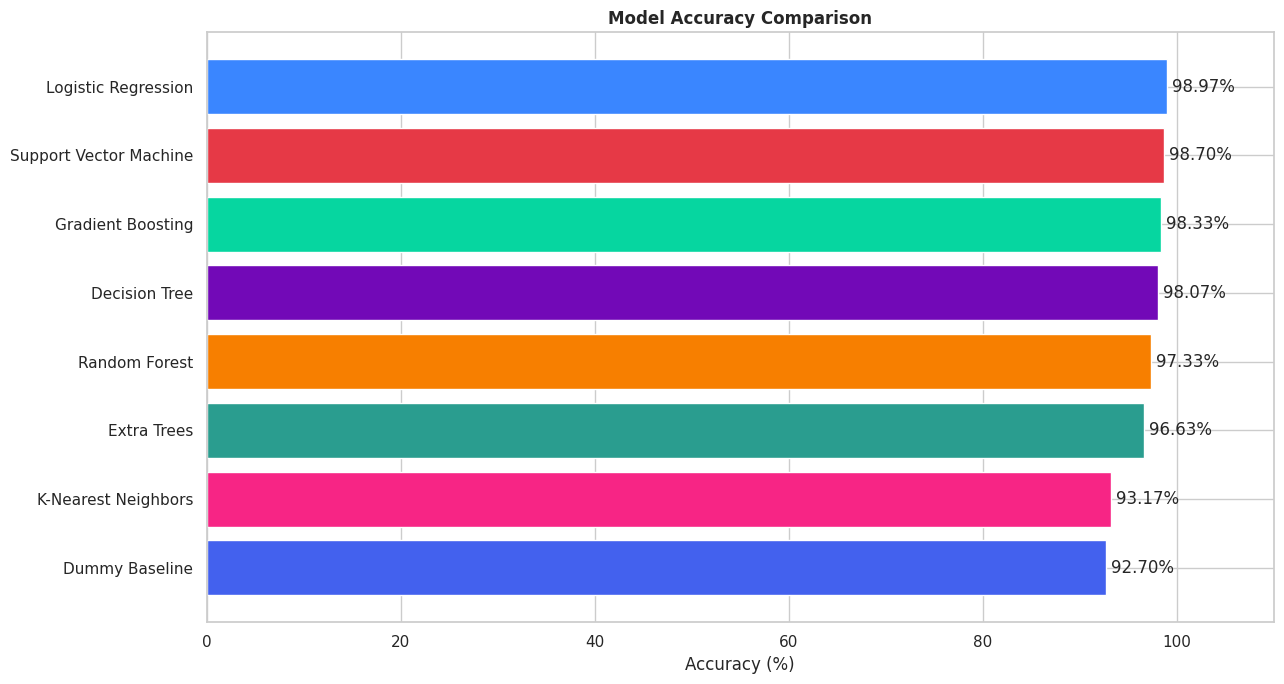

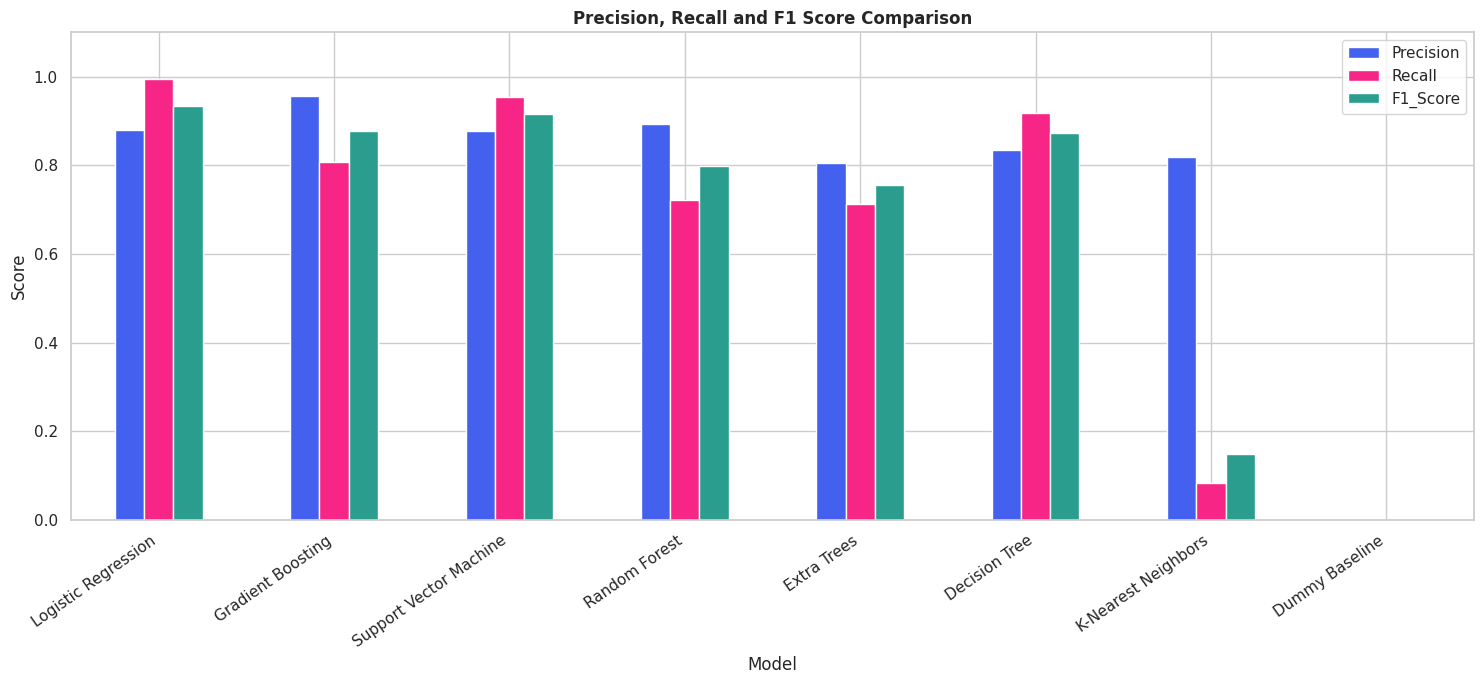

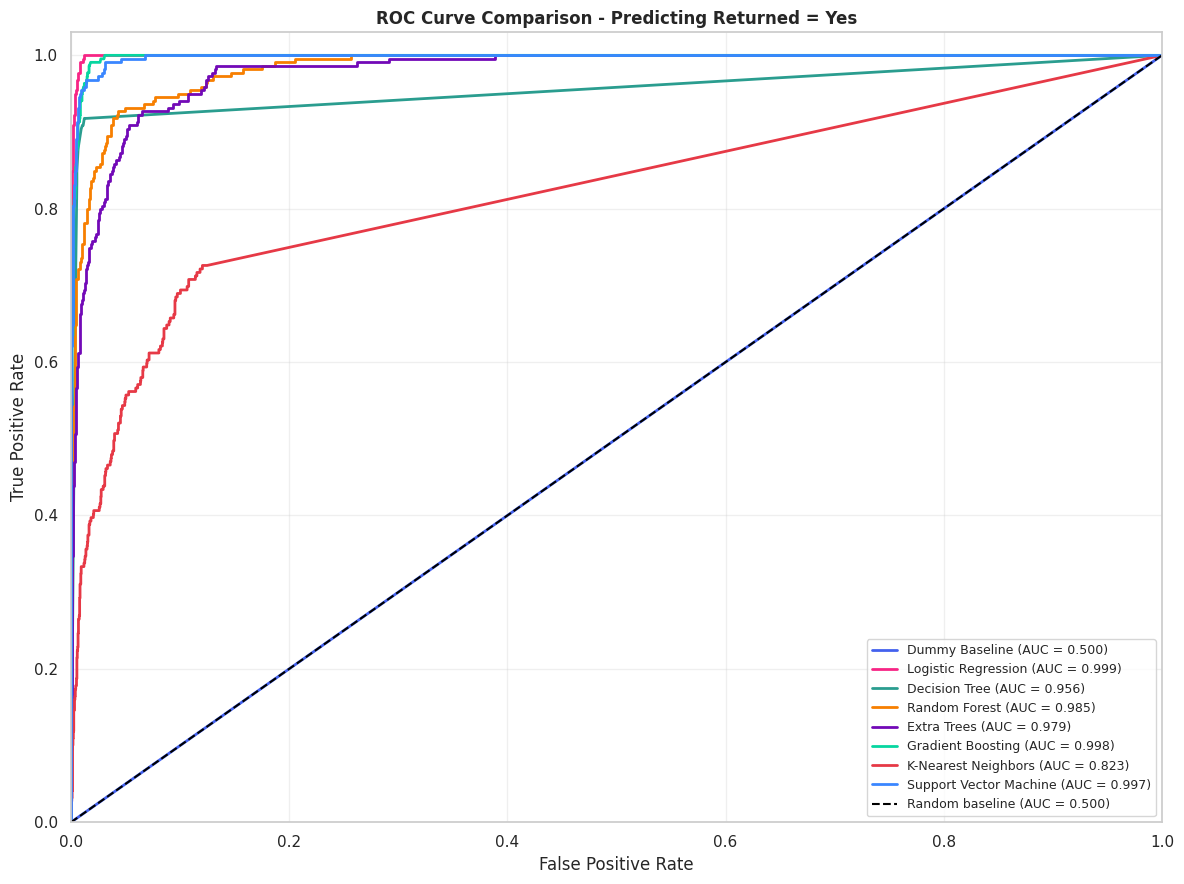

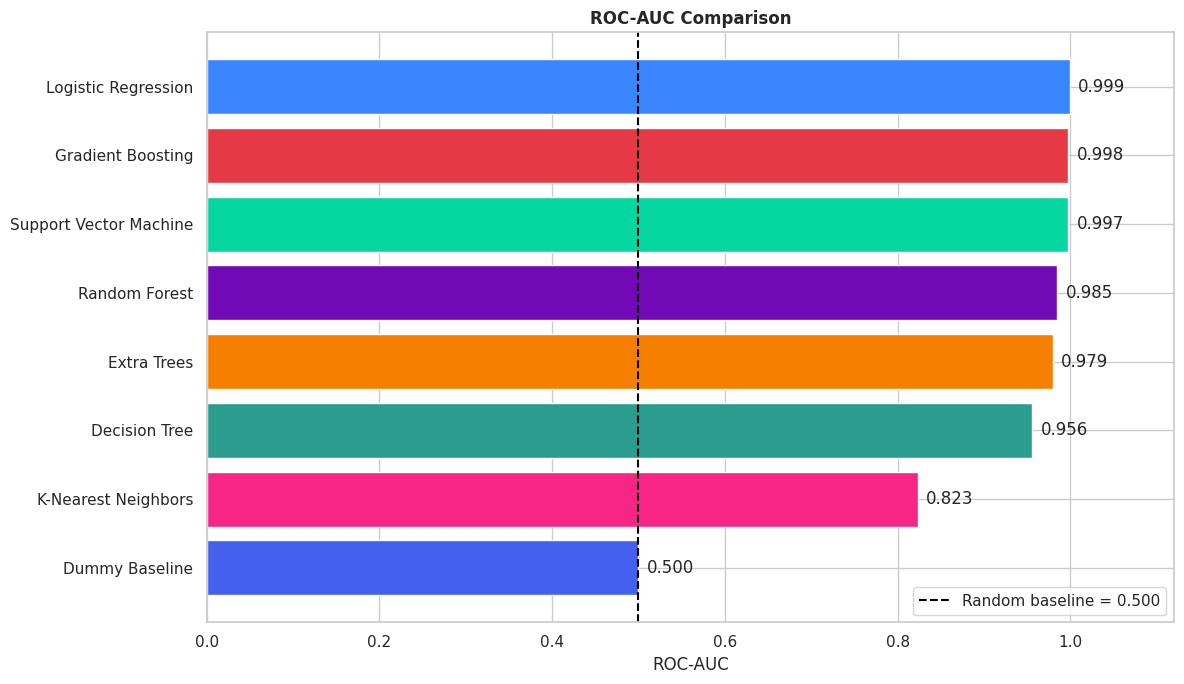


Best model by test ROC-AUC: Logistic Regression


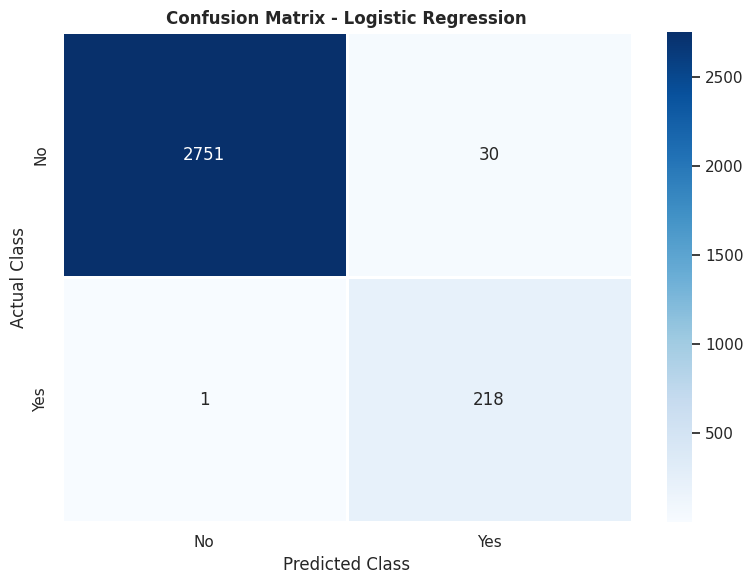


Best model classification report:
              precision    recall  f1-score   support

          No       1.00      0.99      0.99      2781
         Yes       0.88      1.00      0.93       219

    accuracy                           0.99      3000
   macro avg       0.94      0.99      0.96      3000
weighted avg       0.99      0.99      0.99      3000



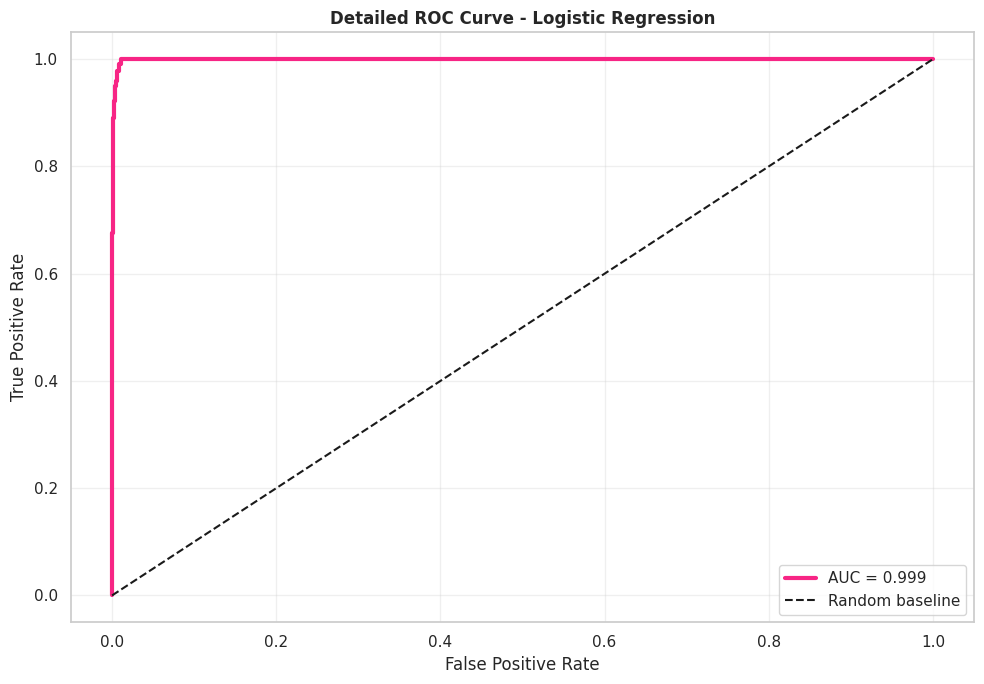


ROC threshold analysis:


,Threshold,False_Positive_Rate,True_Positive_Rate,Specificity,Youden_J
1,1.0000,0.0000,0.0046,1.0000,0.0046
2,0.9965,0.0000,0.5753,1.0000,0.5753
3,0.9964,0.0004,0.5753,0.9996,0.5750
4,0.9921,0.0004,0.6758,0.9996,0.6754
5,0.9921,0.0007,0.6758,0.9993,0.6751
6,0.9826,0.0007,0.7900,0.9993,0.7892
7,0.9821,0.0011,0.7900,0.9989,0.7889
8,0.9653,0.0011,0.8493,0.9989,0.8482
9,0.9596,0.0014,0.8493,0.9986,0.8479
10,0.9438,0.0014,0.8904,0.9986,0.8890



Threshold maximizing Youden's J:


,Value
Threshold,0.446283
False_Positive_Rate,0.011507
True_Positive_Rate,1.000000
Specificity,0.988493
Youden_J,0.988493


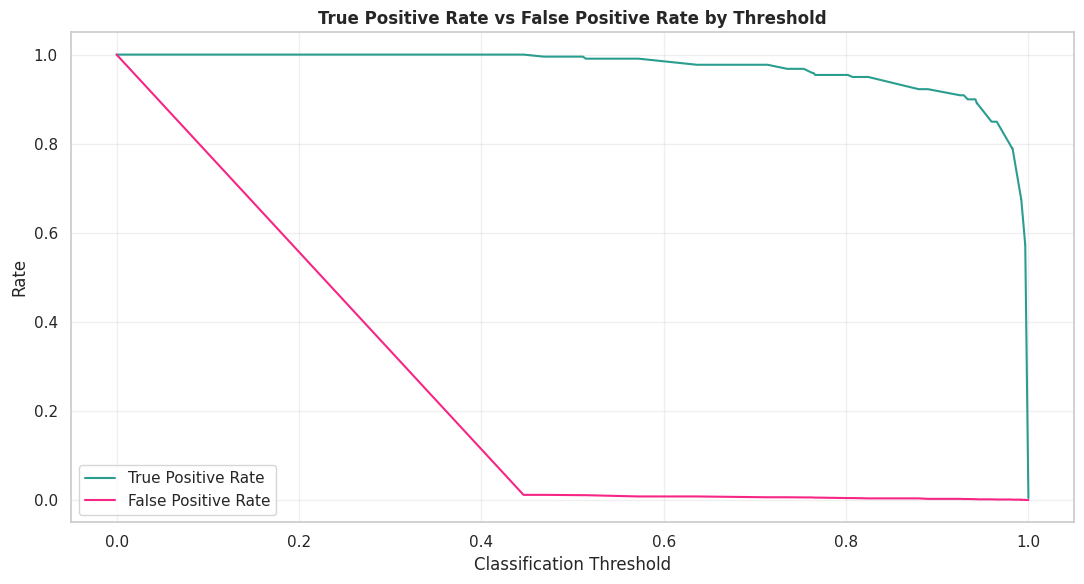


Top 20 features - Random Forest


,Feature,Importance
12,numeric__Profit_Margin_Pct,0.42849
9,numeric__Customer_Satisfaction,0.06493
7,numeric__Profit_INR,0.06425
5,numeric__Net_Sales_INR,0.03413
13,numeric__Average_Order_Value_INR,0.03137
3,numeric__Sales_INR,0.03091
6,numeric__Cost_INR,0.02861
1,numeric__Unit_Price_INR,0.02577
53,categorical__Category_Technology,0.02566
4,numeric__Discount_Amount_INR,0.01946


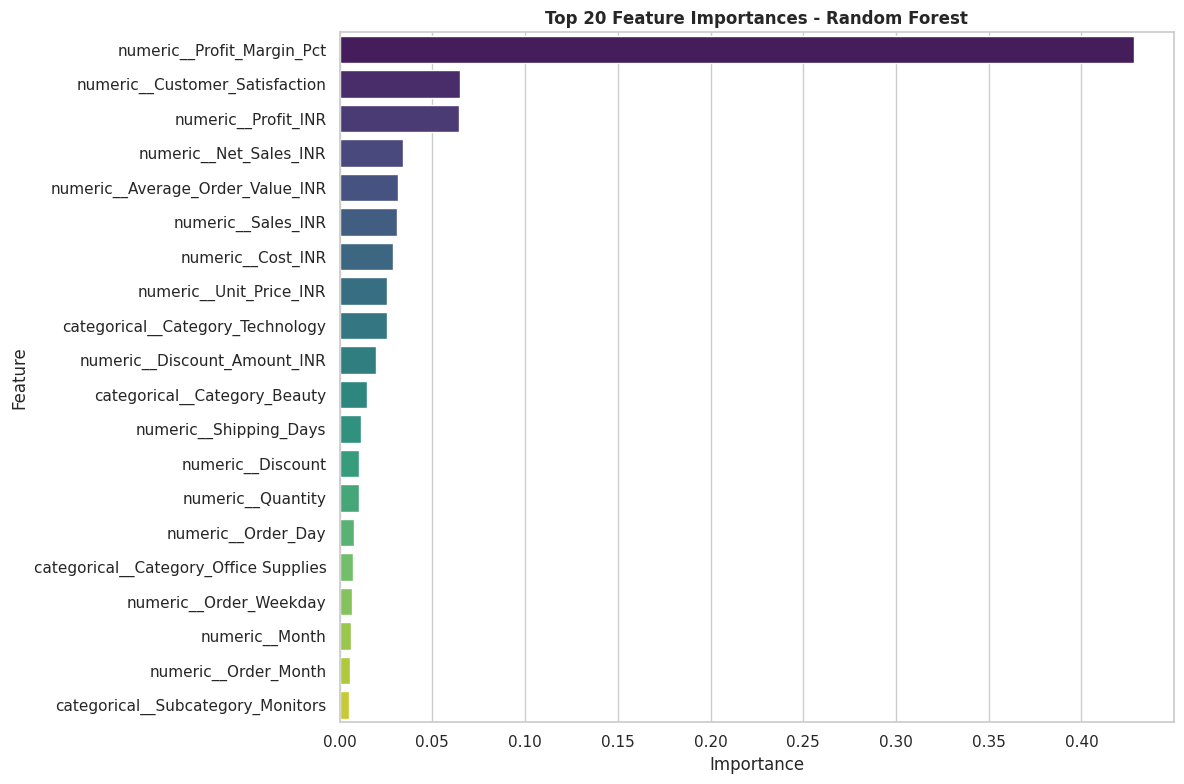

In [14]:
import sklearn
import traceback

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder, StandardScaler, OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# =====================================================================
# 1. SETTINGS
# =====================================================================

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 100

COLORS = [
    "#4361EE", "#F72585", "#2A9D8F", "#F77F00",
    "#7209B7", "#06D6A0", "#E63946", "#3A86FF",
    "#FF006E", "#8338EC", "#FFBE0B"
]

print("=" * 80)
print("SALES RETURN PREDICTION - COMPLETE MACHINE LEARNING")
print("=" * 80)
print("Scikit-learn version:", sklearn.__version__)

# =====================================================================
# 2. LOAD DATASET
# =====================================================================

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' not found. Load your sales dataset into df first."
    )

df = df.copy()
df.columns = df.columns.str.strip()

target_col = "Returned"

required_cols = [
    "Order_ID", "Order_Date", "Customer_ID", "Region", "City",
    "Segment", "Channel", "Category", "Subcategory", "Product_ID",
    "Quantity", "Unit_Price_INR", "Discount", "Sales_INR",
    "Discount_Amount_INR", "Net_Sales_INR", "Cost_INR", "Profit_INR",
    "Shipping_Days", "Returned", "Customer_Satisfaction", "Payment_Method"
]

missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

print("\nOriginal dataset shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

# =====================================================================
# 3. DATA CLEANING
# =====================================================================

# Standardize target labels
df[target_col] = (
    df[target_col]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "yes": "Yes",
        "y": "Yes",
        "true": "Yes",
        "1": "Yes",
        "no": "No",
        "n": "No",
        "false": "No",
        "0": "No"
    })
)

# Convert numeric fields safely
numeric_cols = [
    "Quantity", "Unit_Price_INR", "Discount", "Sales_INR",
    "Discount_Amount_INR", "Net_Sales_INR", "Cost_INR",
    "Profit_INR", "Shipping_Days", "Customer_Satisfaction"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse dates
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce", dayfirst=True
)

# Extract date-based features
df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Day"] = df["Order_Date"].dt.day
df["Order_Weekday"] = df["Order_Date"].dt.dayofweek

# Keep only valid binary target values
df = df[df[target_col].isin(["Yes", "No"])].copy()

if df.empty:
    raise ValueError(
        "No valid Yes/No values in Returned. Check df['Returned'].value_counts()."
    )

# Replace infinite numeric values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove duplicate records
duplicate_count = df.duplicated().sum()
df.drop_duplicates(inplace=True)

print("\nDuplicate rows removed:", duplicate_count)
print("Cleaned dataset shape:", df.shape)

print("\nTarget distribution:")
display(df[target_col].value_counts().to_frame("Count"))

print("\nTarget distribution (%):")
display(
    (df[target_col].value_counts(normalize=True) * 100)
    .round(2).to_frame("Percentage")
)

# =====================================================================
# 4. LABEL ENCODE TARGET
# =====================================================================

target_encoder = LabelEncoder()

y = pd.Series(
    target_encoder.fit_transform(df[target_col]),
    index=df.index,
    name=target_col
)

print("\nTarget label encoding:")

for label, encoded in zip(
    target_encoder.classes_,
    target_encoder.transform(target_encoder.classes_)
):
    print(f"{label} -> {encoded}")

if len(target_encoder.classes_) != 2:
    raise ValueError(
        "This code requires exactly two target classes: Yes and No."
    )

# LabelEncoder sorts alphabetically, so verify which class is positive.
positive_label = "Yes"
positive_index = int(
    np.where(target_encoder.classes_ == positive_label)[0][0]
)

print("Positive class for ROC:", positive_label, "encoded as", positive_index)

# =====================================================================
# 5. FEATURE SELECTION
# =====================================================================

# Exclude identifiers and raw date.
# Customer_ID and Product_ID may cause memorization rather than learning.
# If predicting returns BEFORE shipment, also remove post-order information
# such as Shipping_Days and Customer_Satisfaction.

drop_cols = [
    "Returned",
    "Order_ID",
    "Customer_ID",
    "Product_ID",
    "Order_Date"
]

X = df.drop(columns=drop_cols, errors="ignore").copy()

# Exclude columns with no observed training information or no variation
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

X.drop(columns=constant_cols, inplace=True, errors="ignore")

# Standardize categorical fields to avoid mixed-type encoder failures
for col in X.select_dtypes(include=["object", "category", "string"]).columns:
    X[col] = X[col].map(
        lambda value: str(value).strip() if pd.notna(value) else np.nan
    )

print("\nFeature count:", X.shape[1])
print("Removed constant columns:", constant_cols)
print("Predictor columns:")
print(X.columns.tolist())

if X.empty:
    raise ValueError("No predictor columns available.")

# =====================================================================
# 6. TRAIN-TEST SPLIT
# =====================================================================

class_counts = y.value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "Each target class needs at least two records for a stratified split."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# =====================================================================
# 7. ROBUST PREPROCESSING
# =====================================================================

# Identify data types using training data only
numerical_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

# Convert numerical columns safely and remove infinities
for col in numerical_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove features entirely missing in the training set
all_missing = [
    col for col in X_train.columns
    if X_train[col].isna().all()
]

X_train.drop(columns=all_missing, inplace=True)
X_test.drop(columns=all_missing, inplace=True, errors="ignore")

numerical_features = [
    col for col in numerical_features if col not in all_missing
]

categorical_features = [
    col for col in categorical_features if col not in all_missing
]

# Use consistent string categories, with missing values retained as missing
for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda v: str(v) if pd.notna(v) else np.nan
    )
    X_test[col] = X_test[col].map(
        lambda v: str(v) if pd.notna(v) else np.nan
    )

# OneHotEncoder compatibility: older versions use sparse,
# newer versions use sparse_output.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

transformers = []

if numerical_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numerical_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

if not transformers:
    raise ValueError("No usable numeric or categorical predictors remain.")

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing successful!")
print("Numeric features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("All-missing columns removed:", all_missing)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

# =====================================================================
# 8. DEFINE MACHINE LEARNING MODELS
# =====================================================================

models = {
    "Dummy Baseline": DummyClassifier(
        strategy="prior"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=min(5, len(y_train)),
        weights="distance",
        n_jobs=-1
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

# =====================================================================
# 9. TRAIN AND EVALUATE MODELS
# =====================================================================

results = []
trained_models = {}
roc_data = {}
failed_models = {}

for model_name, model in models.items():

    print("\n" + "=" * 70)
    print("Training:", model_name)
    print("=" * 70)

    try:
        # Use already-preprocessed data to avoid repeated encoding.
        model.fit(X_train_processed, y_train)

        y_pred = model.predict(X_test_processed)

        # Determine probability column for the positive class "Yes"
        class_positions = np.where(model.classes_ == positive_index)[0]

        if len(class_positions) == 0:
            raise ValueError("Positive target class not found in model.classes_.")

        positive_probability_column = int(class_positions[0])

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test_processed)[
                :, positive_probability_column
            ]
        elif hasattr(model, "decision_function"):
            raw_scores = model.decision_function(X_test_processed)
            y_prob = raw_scores if positive_probability_column == 1 else -raw_scores
        else:
            raise ValueError("Model has no probability or decision score output.")

        # Binary metrics use encoded Yes = positive_index
        y_test_binary = (y_test == positive_index).astype(int)
        y_pred_binary = (y_pred == positive_index).astype(int)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test_binary, y_pred_binary, zero_division=0
        )
        recall = recall_score(
            y_test_binary, y_pred_binary, zero_division=0
        )
        f1 = f1_score(
            y_test_binary, y_pred_binary, zero_division=0
        )

        if len(np.unique(y_test_binary)) == 2:
            model_auc = roc_auc_score(y_test_binary, y_prob)
            fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)

            roc_data[model_name] = {
                "fpr": fpr,
                "tpr": tpr,
                "auc": model_auc,
                "thresholds": thresholds
            }
        else:
            model_auc = np.nan

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1_Score": f1,
            "ROC_AUC": model_auc
        })

        trained_models[model_name] = model
        print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
        print(f"Precision : {precision:.4f}")
        print(f"Recall    : {recall:.4f}")
        print(f"F1 Score  : {f1:.4f}")
        print(f"ROC-AUC   : {model_auc:.4f}")

        print("\nClassification report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=target_encoder.classes_,
            zero_division=0
        ))

    except Exception as e:
        failed_models[model_name] = repr(e)
        print("MODEL FAILED:", model_name)
        print("Error type:", type(e).__name__)
        print("Error details:", repr(e))
        traceback.print_exc(limit=2)

if not results:
    print("\nNo models trained successfully.")
    print("\nDetailed errors:")
    for name, error in failed_models.items():
        print(name, "->", error)

    raise RuntimeError(
        "All models failed. Review the detailed error messages above."
    )

# =====================================================================
# 10. MODEL PERFORMANCE COMPARISON
# =====================================================================

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("\n" + "=" * 80)
print("MODEL COMPARISON")
print("=" * 80)
display(results_df.round(4))

# Accuracy comparison
plt.figure(figsize=(13, 7))

plot_df = results_df.sort_values("Accuracy")

bars = plt.barh(
    plot_df["Model"],
    plot_df["Accuracy"] * 100,
    color=[COLORS[i % len(COLORS)] for i in range(len(plot_df))]
)

for bar in bars:
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

# Precision, recall and F1 score
results_df.set_index("Model")[
    ["Precision", "Recall", "F1_Score"]
].plot(
    kind="bar",
    figsize=(15, 7),
    color=["#4361EE", "#F72585", "#2A9D8F"]
)

plt.title("Precision, Recall and F1 Score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# =====================================================================
# 11. ROC CURVES FOR ALL MODELS
# =====================================================================

plt.figure(figsize=(12, 9))

for i, (name, values) in enumerate(roc_data.items()):
    plt.plot(
        values["fpr"],
        values["tpr"],
        linewidth=2,
        color=COLORS[i % len(COLORS)],
        label=f"{name} (AUC = {values['auc']:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random baseline (AUC = 0.500)"
)

plt.title("ROC Curve Comparison - Predicting Returned = Yes")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.03)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================================
# 12. AUC COMPARISON
# =====================================================================

auc_df = results_df.dropna(subset=["ROC_AUC"]).sort_values("ROC_AUC")

plt.figure(figsize=(12, 7))

bars = plt.barh(
    auc_df["Model"],
    auc_df["ROC_AUC"],
    color=[COLORS[i % len(COLORS)] for i in range(len(auc_df))]
)

for bar in bars:
    plt.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.3f}",
        va="center"
    )

plt.axvline(
    0.5, color="black", linestyle="--",
    label="Random baseline = 0.500"
)
plt.title("ROC-AUC Comparison")
plt.xlabel("ROC-AUC")
plt.xlim(0, 1.12)
plt.legend()
plt.tight_layout()
plt.show()

# =====================================================================
# 13. BEST MODEL CONFUSION MATRIX
# =====================================================================

if not auc_df.empty:
    best_model_name = auc_df.iloc[-1]["Model"]
else:
    best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]
best_pred = best_model.predict(X_test_processed)

print("\nBest model by test ROC-AUC:", best_model_name)

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_,
    linewidths=1
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("\nBest model classification report:")
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=target_encoder.classes_,
    zero_division=0
))

# =====================================================================
# 14. DETAILED ROC CURVE AND THRESHOLD ANALYSIS
# =====================================================================

best_roc = roc_data.get(best_model_name)

if best_roc is not None:

    plt.figure(figsize=(10, 7))

    plt.plot(
        best_roc["fpr"],
        best_roc["tpr"],
        color="#F72585",
        linewidth=3,
        label=f"AUC = {best_roc['auc']:.3f}"
    )

    plt.plot([0, 1], [0, 1], "k--", label="Random baseline")

    plt.title(f"Detailed ROC Curve - {best_model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    threshold_df = pd.DataFrame({
        "Threshold": best_roc["thresholds"],
        "False_Positive_Rate": best_roc["fpr"],
        "True_Positive_Rate": best_roc["tpr"]
    })

    threshold_df["Specificity"] = (
        1 - threshold_df["False_Positive_Rate"]
    )

    threshold_df["Youden_J"] = (
        threshold_df["True_Positive_Rate"]
        + threshold_df["Specificity"] - 1
    )

    finite_threshold_df = threshold_df[
        np.isfinite(threshold_df["Threshold"])
    ]

    print("\nROC threshold analysis:")
    display(finite_threshold_df.head(15).round(4))

    if not finite_threshold_df.empty:
        best_threshold = finite_threshold_df.loc[
            finite_threshold_df["Youden_J"].idxmax()
        ]

        print("\nThreshold maximizing Youden's J:")
        display(best_threshold.to_frame("Value"))

        plt.figure(figsize=(11, 6))

        plt.plot(
            threshold_df["Threshold"],
            threshold_df["True_Positive_Rate"],
            label="True Positive Rate",
            color="#2A9D8F"
        )

        plt.plot(
            threshold_df["Threshold"],
            threshold_df["False_Positive_Rate"],
            label="False Positive Rate",
            color="#F72585"
        )

        plt.xlabel("Classification Threshold")
        plt.ylabel("Rate")
        plt.title("True Positive Rate vs False Positive Rate by Threshold")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# =====================================================================
# 15. FEATURE IMPORTANCE
# =====================================================================

# Retrieve encoded feature names for tree-based models
try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = np.array([
        f"Feature_{i}" for i in range(X_train_processed.shape[1])
    ])

importance_found = False

for model_name in [
    "Random Forest",
    "Extra Trees",
    "Decision Tree",
    "Gradient Boosting"
]:

    if model_name not in trained_models:
        continue

    fitted_model = trained_models[model_name]

    if not hasattr(fitted_model, "feature_importances_"):
        continue

    importances = fitted_model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(
        "Importance", ascending=False
    ).head(20)

    print(f"\nTop 20 features - {model_name}")
    display(importance_df.round(5))

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature",
        hue="Feature",
        palette="viridis",
        legend=False
    )

    plt.title(f"Top 20 Feature Importances - {model_name}")
    plt.tight_layout()
    plt.show()

    importance_found = True
    break

if not importance_found:
    print("Feature importance is unavailable for the fitted models.")
